# Predicción de Diabetes Mediante Técnicas de Minería de Datos Aplicadas a Indicadores de Salud

**Proyecto de aula – Entrega final (Corte 3): ajuste, evaluación final, modelo exportado y aplicación en Streamlit**
**Universidad de la Costa (CUC) – Departamento de Ciencias de la Computación y Electrónica – Ingeniería de Sistemas**
**Curso:** Minería de Datos · **Profesor:** José Escorcia Gutiérrez

**Integrantes:**
- Alison Lara Correa – 25786
- Roger Bolaño Truyol – 25368
- Valeri Alvarez Blanco – 25158

**Tipo de proyecto:** Clasificación supervisada (binaria).

**Pregunta de investigación:** ¿Es posible predecir si una paciente presenta diabetes a partir de indicadores clínicos y demográficos no invasivos (glucosa, presión arterial, IMC, insulina, edad, antecedentes familiares, etc.), y qué modelo de clasificación ofrece el mejor equilibrio entre detectar a las pacientes diabéticas (recall) y evitar falsas alarmas (precision)?

**Dataset:** Pima Indians Diabetes Dataset (National Institute of Diabetes and Digestive and Kidney Diseases), archivo `diabetes_dataset.csv` incluido en el repositorio: 768 registros y 9 columnas. **Variable objetivo:** `Outcome` (1 = diabetes, 0 = no diabetes).

**Cómo está organizado este notebook.** Las secciones 1 a 8 conservan y consolidan el trabajo de los avances 1 y 2 (descripción de datos, calidad, limpieza, preparación y EDA). Las secciones 9 a 15 son nuevas de esta entrega: línea base, ajuste de hiperparámetros, selección del modelo, umbral de decisión, evaluación final, análisis de errores, exportación del modelo que usa la aplicación de Streamlit, discusión y conclusiones. La sección 16 reúne la declaración de uso de inteligencia artificial de los tres cortes.

**Reproducibilidad.** Ejecutar el notebook completo, de arriba abajo, desde la carpeta del repositorio (donde está `diabetes_dataset.csv`). Todas las cifras que se interpretan en las secciones 9 a 15 se calculan en las celdas de código; no se copiaron valores de ejecuciones anteriores. El notebook escribe `modelo_diabetes.joblib` y `casos_referencia.csv`, que son los archivos que utiliza la aplicación y sus pruebas.

## 0. Cambios frente al segundo avance

| Aspecto | Segundo avance | Entrega final | Justificación |
|---|---|---|---|
| Línea base | No se incluyó | `DummyClassifier` que siempre predice la clase mayoritaria | La guía exige comparar con una línea base; muestra qué tan engañoso es el accuracy con clases 65/35. |
| Hiperparámetros | Valores por defecto de scikit-learn | Búsqueda en malla con validación cruzada de 5 particiones **solo sobre el entrenamiento** | Es la mejora anunciada al cierre del avance 2. El conjunto de prueba no interviene en ninguna decisión. |
| Balanceo | Solo `class_weight="balanced"` en regresión logística | Pesos de clase en todos los modelos ajustados y evaluación de SMOTE dentro del `Pipeline` | Se evalúa SMOTE (anunciado en el avance 2) aplicándolo únicamente a los datos de entrenamiento de cada partición. |
| Imputación | Mediana (dentro del `Pipeline`) | Se compara mediana, mediana con indicador de faltante y KNN | Mejora anunciada en el avance 2: "comparación con otros imputadores". |
| Umbral de decisión | 0,5 fijo | Se estudia con probabilidades fuera de muestra del entrenamiento | Mejora anunciada en el avance 2; permite documentar el compromiso entre recall y precision. |
| Criterio de selección | Recall y F1 en prueba (una sola partición) | F1 de la clase diabética en validación cruzada, definido antes de comparar | Evita elegir mirando el conjunto de prueba, que tiene solo 154 registros. |
| Incertidumbre | Sin intervalos | Intervalos bootstrap de las métricas en prueba | Con 54 pacientes diabéticas en prueba, una sola cifra puntual puede confundir. |
| Modelo final | Regresión logística balanceada (elegida con los resultados de una sola partición) | Lo determina la regla de la sección 9; en la ejecución entregada es el **Random Forest balanceado ajustado** | Es un cambio frente al avance 2 y se justifica en la sección 10 (mayor F1 en validación cruzada). La diferencia en prueba es pequeña y se discute con intervalos de confianza. |
| Despliegue | No existía | Modelo exportado (`modelo_diabetes.joblib`) y aplicación `app.py` en Streamlit | La aplicación carga exactamente el pipeline evaluado aquí. |

Las cifras del avance 2 se **re-ejecutaron** en la sección 9 y coinciden con las reportadas entonces, de modo que los resultados nuevos son comparables con los anteriores. La preparación de datos y el EDA (secciones 1 a 8) no cambiaron, salvo la corrección de redacción de frases que anunciaban trabajo futuro.

## 1. Descripción del Dataset (2.1)

- **Nombre del dataset:** Pima Indians Diabetes Dataset
- **Fuente / enlace de descarga:** Dataset de referencia sugerido para el proyecto: [Diabetes Dataset - Kaggle](https://www.kaggle.com/datasets/amineipad/diabetes-dataset). El archivo `diabetes_dataset.csv` del repositorio contiene los mismos 768 registros de la versión pública del *National Institute of Diabetes and Digestive and Kidney Diseases* distribuida en el repositorio de datasets de referencia de Jason Brownlee (se verificó que los valores coinciden celda por celda; la única diferencia es que el archivo del repositorio incluye la fila de encabezados): https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv
- **Descripción del contenido:** El dataset contiene información clínica y demográfica de mujeres de al menos 21 años, de ascendencia Pima (Arizona, EE. UU.), utilizada históricamente para predecir la presencia de diabetes tipo 2 a partir de indicadores médicos no invasivos (glucosa, presión arterial, índice de masa corporal, número de embarazos, entre otros).
- **Número de filas y columnas:** 768 filas (pacientes) y 9 columnas (8 variables predictoras + 1 variable objetivo).
- **Propósito general del dataset:** Servir como base para construir modelos de clasificación que permitan predecir el riesgo de diabetes en una paciente a partir de variables clínicas fácilmente medibles, apoyando la detección temprana y la priorización de exámenes complementarios.

In [1]:
import os
os.makedirs("figs", exist_ok=True)  # carpeta donde se guardan las figuras

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

# Carga del dataset
df = pd.read_csv("diabetes_dataset.csv")
print(f"Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()

Dimensiones del dataset: 768 filas x 9 columnas


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Descripción de Variables (2.2)

| Variable | Descripción |
|---|---|
| `Pregnancies` | Número de embarazos que ha tenido la paciente |
| `Glucose` | Concentración de glucosa en plasma a las 2 horas de una prueba de tolerancia oral (mg/dL) |
| `BloodPressure` | Presión arterial diastólica (mm Hg) |
| `SkinThickness` | Espesor del pliegue cutáneo del tríceps (mm) |
| `Insulin` | Insulina sérica a las 2 horas (mu U/ml) |
| `BMI` | Índice de masa corporal (peso en kg / (altura en m)^2) |
| `DiabetesPedigreeFunction` | Puntaje que estima la probabilidad de diabetes según antecedentes familiares |
| `Age` | Edad de la paciente (años) |
| `Outcome` | **Variable objetivo (target):** 1 = presenta diabetes, 0 = no presenta diabetes |

**Tipo de proyecto:** Clasificación binaria. La variable objetivo identificada es `Outcome`. El resto de las variables (`Pregnancies`, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction`, `Age`) son las variables predictoras que se usan para entrenar los modelos de clasificación.

## 3. Carga de Datos y Exploración Inicial (2.3)

In [2]:
# Tamaño del dataset
print("Forma del dataset (filas, columnas):", df.shape)

Forma del dataset (filas, columnas): (768, 9)


In [3]:
# Tipos de datos
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [4]:
# Estadísticas descriptivas generales
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [5]:
# Identificación de variables numéricas y categóricas
numericas = df.select_dtypes(include=[np.number]).columns.tolist()
categoricas = df.select_dtypes(exclude=[np.number]).columns.tolist()

print("Variables numéricas:", numericas)
print("Variables categóricas:", categoricas if categoricas else "No se identificaron variables categóricas explícitas.")
print("\nNota: 'Outcome' es numérica (0/1) pero funciona conceptualmente como variable categórica binaria (target).")

Variables numéricas: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
Variables categóricas: No se identificaron variables categóricas explícitas.

Nota: 'Outcome' es numérica (0/1) pero funciona conceptualmente como variable categórica binaria (target).


## 4. Diagnóstico Inicial de Calidad de Datos (2.4)

Se revisan valores faltantes explícitos, duplicados, variables mal codificadas, datos inconsistentes y posibles outliers.

In [6]:
# Valores faltantes explícitos (NaN)
print("Valores nulos por columna:")
print(df.isnull().sum())

Valores nulos por columna:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [7]:
# Registros duplicados
duplicados = df.duplicated().sum()
print(f"Número de registros duplicados: {duplicados}")

Número de registros duplicados: 0


In [8]:
# Valores en 0 en columnas donde 0 no es fisiológicamente válido
# (esto revela 'missing values disfrazados' de ceros, un problema común de este dataset)
cols_check = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
ceros = (df[cols_check] == 0).sum()
print("Cantidad de valores en 0 (probablemente datos faltantes codificados como 0):")
print(ceros)
print("\nPorcentaje sobre el total de registros:")
print((ceros / len(df) * 100).round(2))

Cantidad de valores en 0 (probablemente datos faltantes codificados como 0):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Porcentaje sobre el total de registros:
Glucose           0.65
BloodPressure     4.56
SkinThickness    29.56
Insulin          48.70
BMI               1.43
dtype: float64


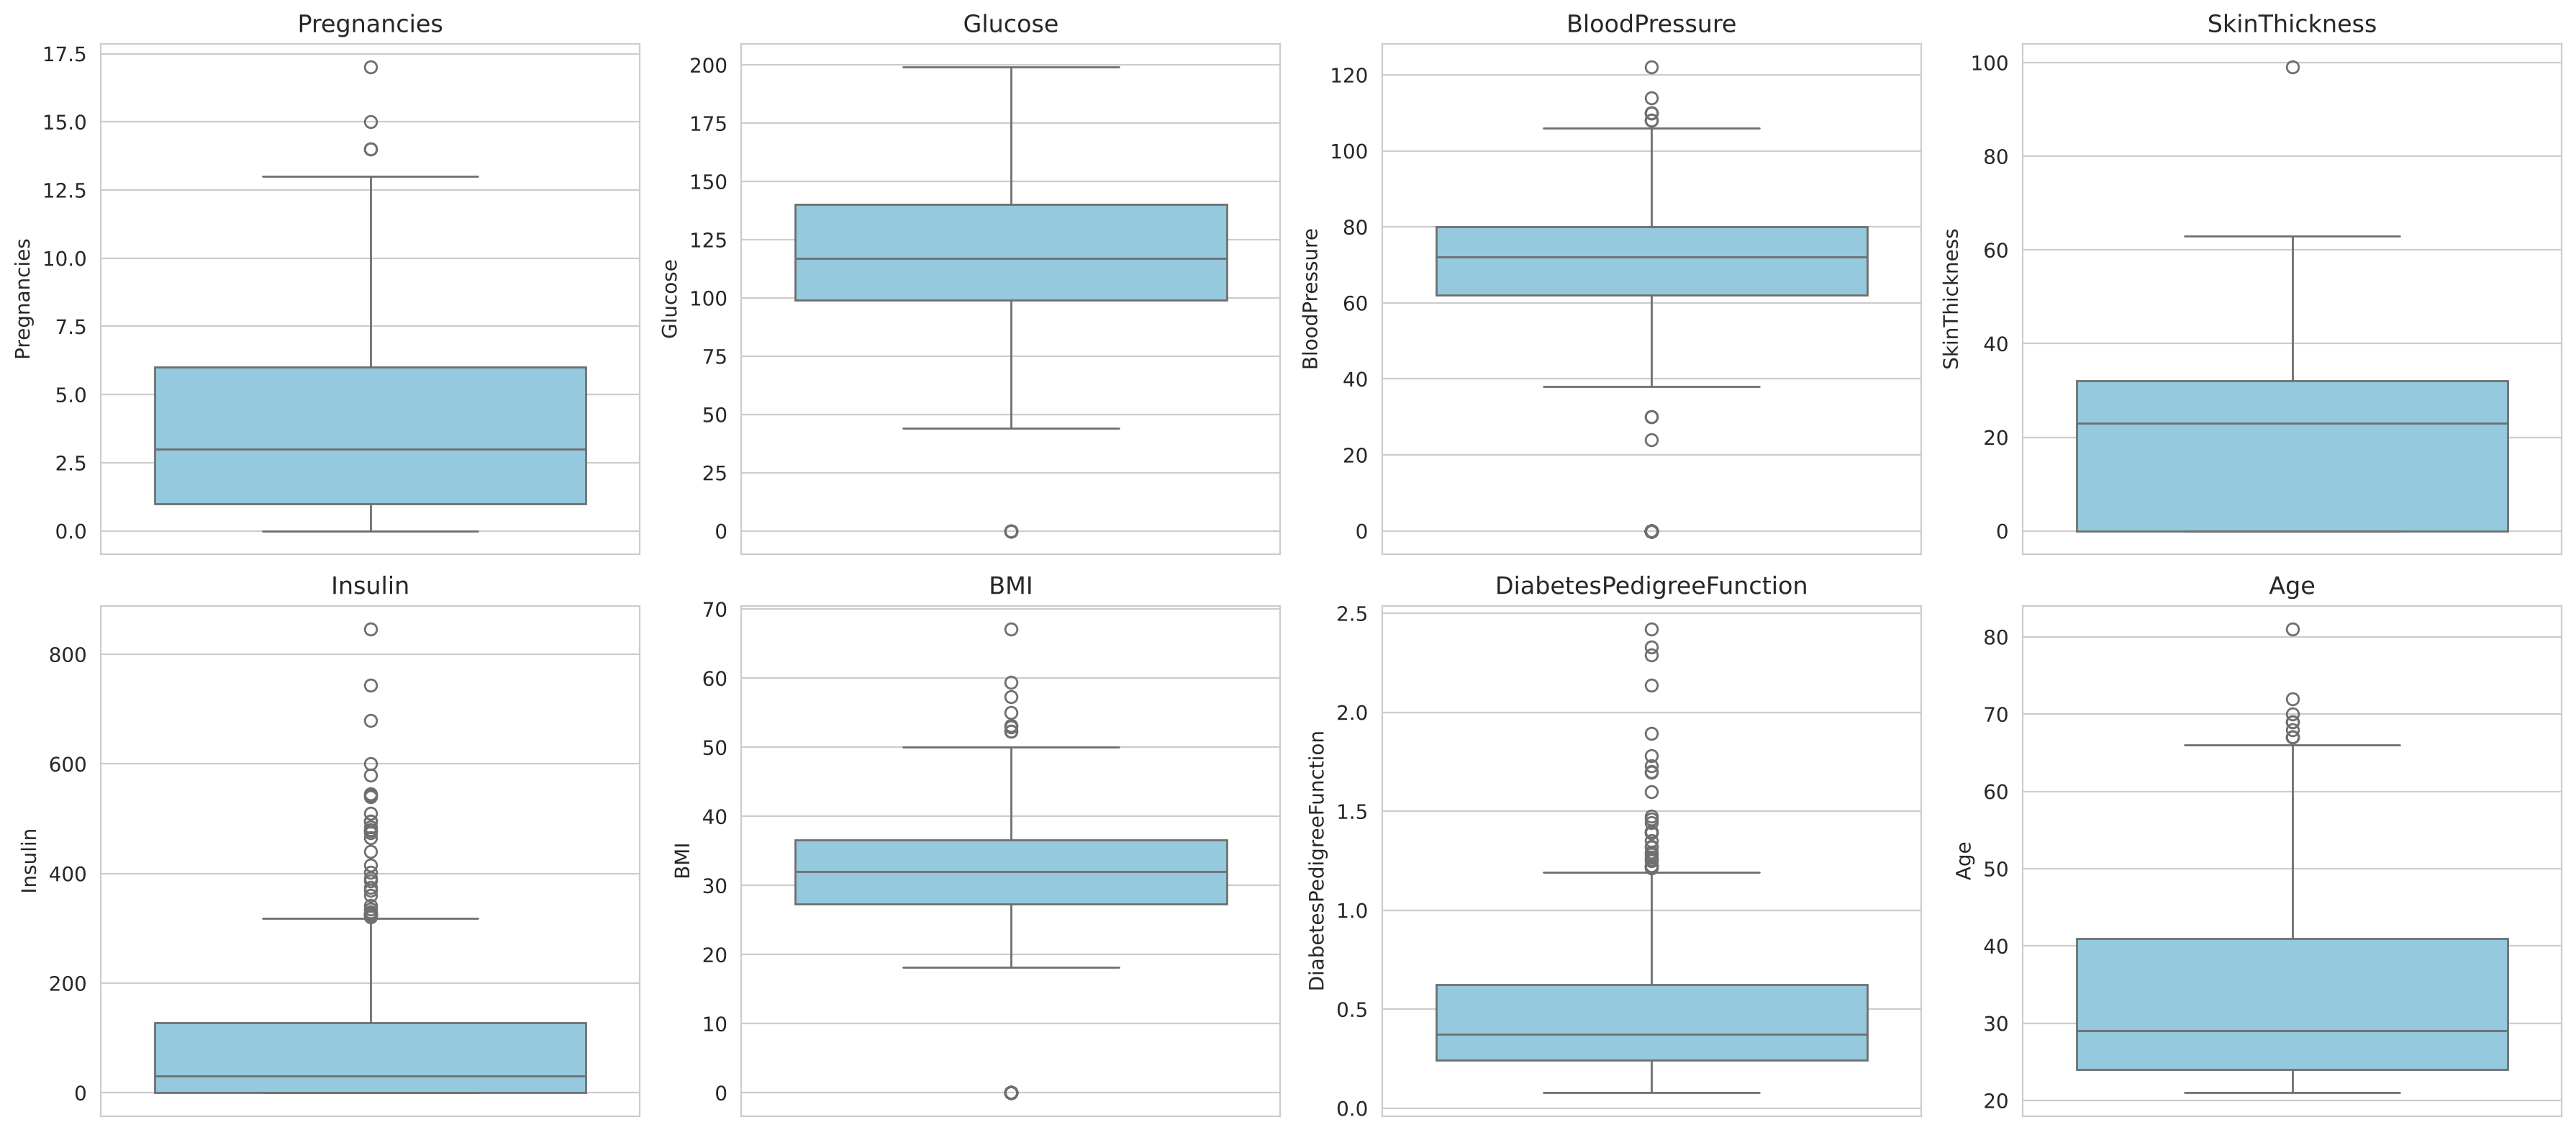

In [9]:
# Revisión de posibles outliers con boxplots
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(numericas[:-1]):  # excluye Outcome
    sns.boxplot(y=df[col], ax=axes[i], color="skyblue")
    axes[i].set_title(col)
plt.tight_layout()
plt.savefig("figs/outliers_boxplots.png", dpi=100)
plt.show()

**Diagnóstico encontrado:**
- No hay valores `NaN` explícitos en el dataset.
- No se encontraron registros duplicados.
- Sin embargo, columnas como `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` y `BMI` presentan una cantidad considerable de valores en **0**, lo cual es clínicamente imposible (una persona viva no puede tener presión arterial o glucosa igual a 0). Esto indica **datos faltantes codificados como 0**, un problema de calidad que debe corregirse.
- `Insulin` y `SkinThickness` son las variables con mayor proporción de estos "ceros ocultos", y los boxplots muestran además la presencia de **outliers** (valores extremos) en `Insulin`, `DiabetesPedigreeFunction` y `Pregnancies`.
- No se identifican columnas de bajo valor analítico que deban eliminarse en esta primera fase; todas las variables tienen sustento clínico para el problema de clasificación.

## 5. Limpieza Inicial de Datos en Python (2.5)

In [10]:
# 1. Copia de trabajo para conservar el dataset original
df_clean = df.copy()

# 2. Corrección de nombres de columnas (estandarización a snake_case)
df_clean.columns = [c.strip().lower() for c in df_clean.columns]
df_clean.rename(columns={"diabetespedigreefunction": "diabetes_pedigree_function"}, inplace=True)
print(df_clean.columns.tolist())

['pregnancies', 'glucose', 'bloodpressure', 'skinthickness', 'insulin', 'bmi', 'diabetes_pedigree_function', 'age', 'outcome']


In [11]:
# 3. Tratamiento de valores faltantes (ceros disfrazados)
# Se reemplazan los ceros no válidos por NaN y luego se imputan con la mediana de cada variable
cols_fix = ["glucose", "bloodpressure", "skinthickness", "insulin", "bmi"]

for col in cols_fix:
    df_clean[col] = df_clean[col].replace(0, np.nan)

print("Valores faltantes tras marcar los ceros como NaN:")
print(df_clean[cols_fix].isnull().sum())

Valores faltantes tras marcar los ceros como NaN:
glucose            5
bloodpressure     35
skinthickness    227
insulin          374
bmi               11
dtype: int64


In [12]:
# Imputación con la mediana (más robusta que la media ante outliers)
for col in cols_fix:
    mediana = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(mediana)

print("Valores faltantes después de la imputación:")
print(df_clean[cols_fix].isnull().sum())

Valores faltantes después de la imputación:
glucose          0
bloodpressure    0
skinthickness    0
insulin          0
bmi              0
dtype: int64


In [13]:
# 4. Eliminación de duplicados (verificación, aunque no se encontraron en el diagnóstico)
antes = df_clean.shape[0]
df_clean = df_clean.drop_duplicates()
print(f"Registros antes: {antes} | Registros después de eliminar duplicados: {df_clean.shape[0]}")

Registros antes: 768 | Registros después de eliminar duplicados: 768


In [14]:
# 5. Conversión de tipos de datos
df_clean["outcome"] = df_clean["outcome"].astype("category")
df_clean["pregnancies"] = df_clean["pregnancies"].astype(int)
print(df_clean.dtypes)

pregnancies                      int64
glucose                        float64
bloodpressure                  float64
skinthickness                  float64
insulin                        float64
bmi                            float64
diabetes_pedigree_function     float64
age                              int64
outcome                       category
dtype: object


In [15]:
# 6. Revisión de outliers mediante el método del rango intercuartílico (IQR)
# Aquí solo se reporta; la decisión definitiva (conservarlos) se justifica en la sección 7.
def detectar_outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    return ((serie < lim_inf) | (serie > lim_sup)).sum()

for col in ["glucose", "bloodpressure", "bmi", "insulin", "diabetes_pedigree_function", "age"]:
    n_out = detectar_outliers_iqr(df_clean[col])
    print(f"{col}: {n_out} posibles outliers (método IQR)")

glucose: 0 posibles outliers (método IQR)
bloodpressure: 14 posibles outliers (método IQR)
bmi: 8 posibles outliers (método IQR)
insulin: 346 posibles outliers (método IQR)
diabetes_pedigree_function: 29 posibles outliers (método IQR)
age: 9 posibles outliers (método IQR)


In [16]:
# 7. Estandarización de la variable categórica objetivo (etiquetas legibles para el EDA)
df_clean["outcome_label"] = df_clean["outcome"].map({0: "No diabético", 1: "Diabético"})
df_clean[["outcome", "outcome_label"]].head()

,outcome,outcome_label
0,1,Diabético
1,0,No diabético
2,1,Diabético
3,0,No diabético
4,1,Diabético


In [17]:
# Vista final del dataset limpio
df_clean.describe()

,pregnancies,glucose,bloodpressure,skinthickness,insulin,bmi,diabetes_pedigree_function,age
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.656250,72.386719,29.108073,140.671875,32.455208,0.471876,33.240885
std,3.369578,30.438286,12.096642,8.791221,86.383060,6.875177,0.331329,11.760232
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000


## 6. Visualizaciones Iniciales (2.6)

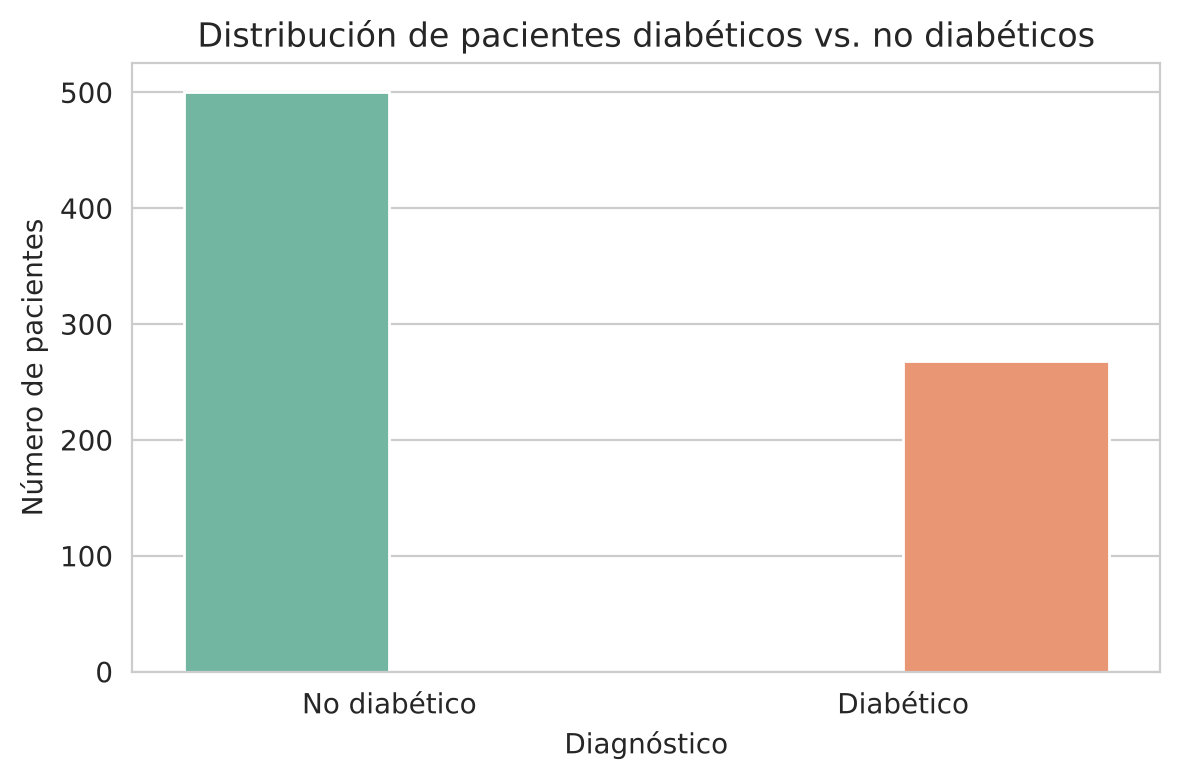

outcome_label
No diabético    65.1
Diabético       34.9
Name: proportion, dtype: float64


In [18]:
# Visualización 1: Distribución de la variable objetivo (balance de clases)
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="outcome_label", hue="outcome_label", data=df_clean, palette="Set2", legend=False)
plt.title("Distribución de pacientes diabéticos vs. no diabéticos")
plt.xlabel("Diagnóstico")
plt.ylabel("Número de pacientes")
plt.tight_layout()
plt.savefig("figs/viz1_balance_clases.png", dpi=100)
plt.show()

print(df_clean["outcome_label"].value_counts(normalize=True).round(3) * 100)

**Interpretación:** La clase "No diabético" representa aproximadamente el 65% de los registros y "Diabético" el 35% restante. Existe un **desbalance moderado de clases**, un aspecto que condiciona el entrenamiento y la evaluación de los modelos (se aborda con pesos de clase y con la evaluación de SMOTE en la sección 10).

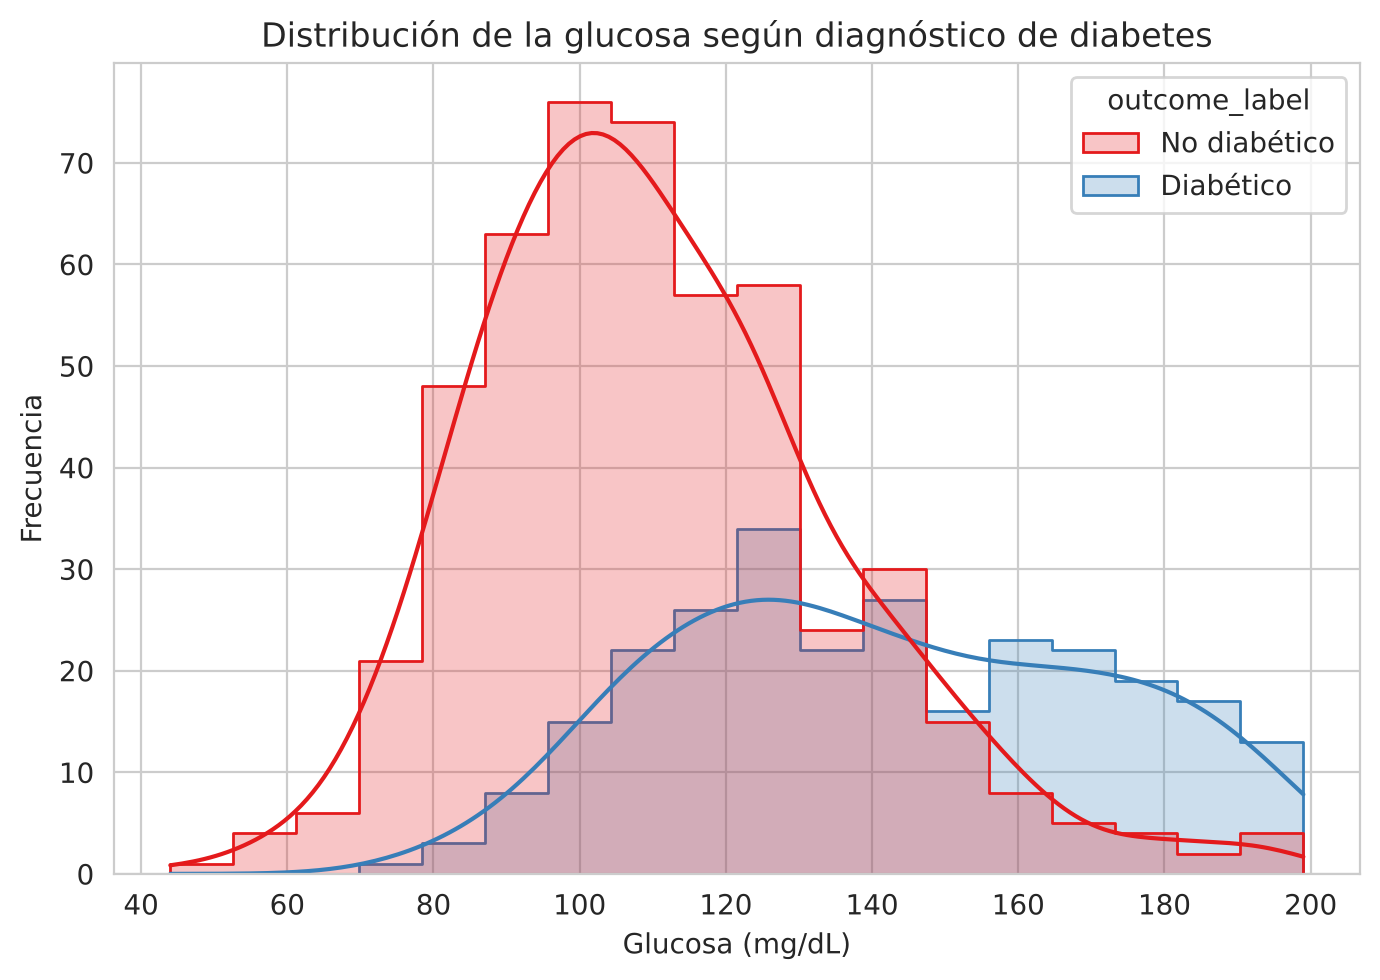

In [19]:
# Visualización 2: Distribución de Glucosa según diagnóstico
plt.figure(figsize=(7, 5))
sns.histplot(data=df_clean, x="glucose", hue="outcome_label", kde=True, element="step", palette="Set1")
plt.title("Distribución de la glucosa según diagnóstico de diabetes")
plt.xlabel("Glucosa (mg/dL)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.savefig("figs/viz2_glucosa.png", dpi=100)
plt.show()

**Interpretación:** Se observa que las pacientes diagnosticadas con diabetes tienden a concentrarse en niveles de glucosa más altos que las no diabéticas, lo cual es consistente con el criterio clínico de que la glucosa es uno de los indicadores más determinantes para el diagnóstico de la enfermedad. Esta variable probablemente tendrá alta importancia predictiva en los modelos de clasificación.

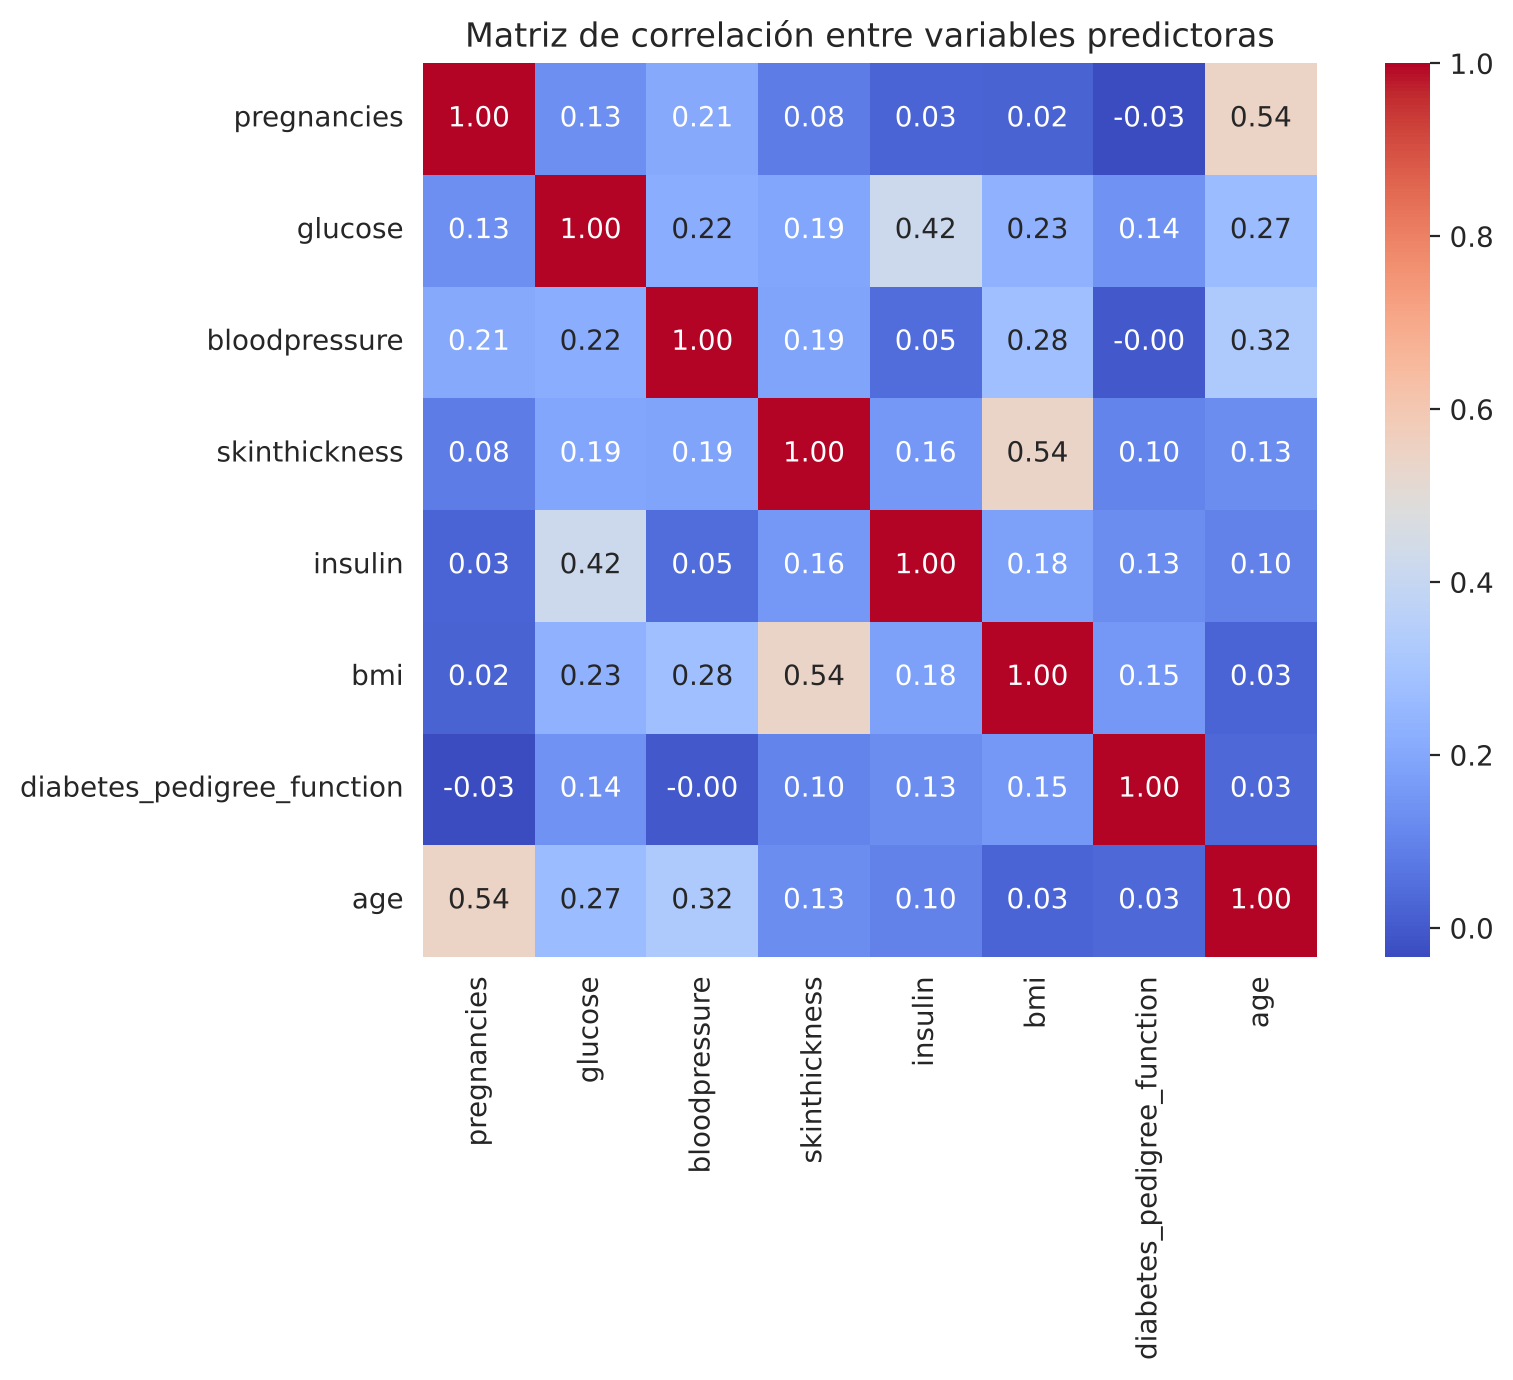

In [20]:
# Visualización 3: Matriz de correlación entre variables numéricas
plt.figure(figsize=(9, 7))
corr = df_clean[["pregnancies","glucose","bloodpressure","skinthickness",
                  "insulin","bmi","diabetes_pedigree_function","age"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Matriz de correlación entre variables predictoras")
plt.tight_layout()
plt.savefig("figs/viz3_correlacion.png", dpi=100)
plt.show()

**Interpretación:** La correlación más fuerte se observa entre `skinthickness` e `insulin`, y entre `age` y `pregnancies`, lo cual tiene sentido fisiológico y demográfico. Ninguna correlación es extremadamente alta (> 0.9), por lo que en principio no se anticipan problemas graves de multicolinealidad para el modelado.

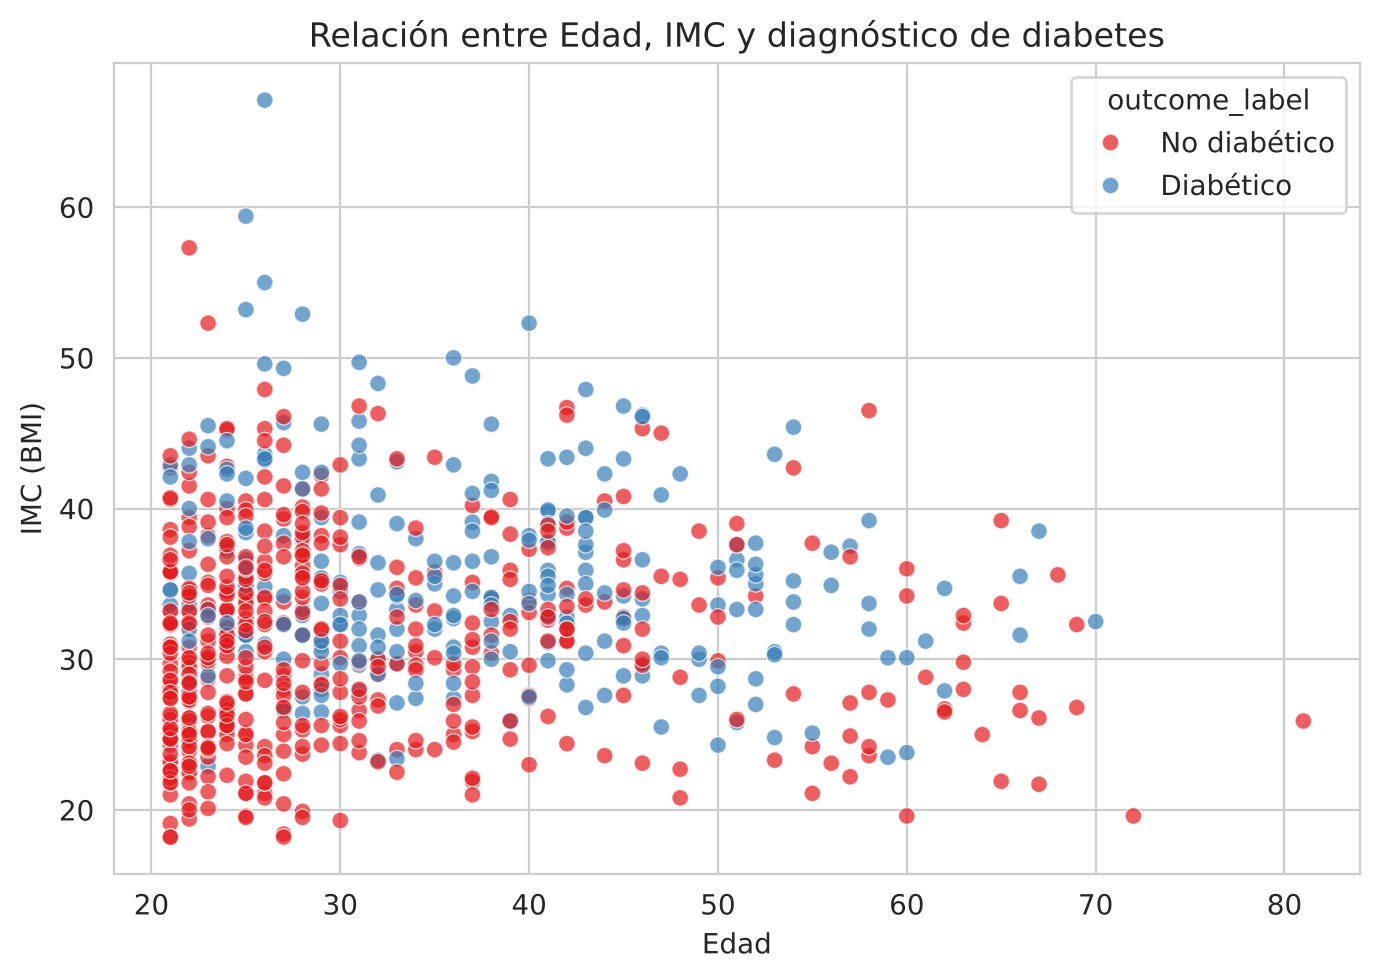

In [21]:
# Visualización 4 (extra): Relación entre edad, IMC y diagnóstico
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_clean, x="age", y="bmi", hue="outcome_label", alpha=0.7, palette="Set1")
plt.title("Relación entre Edad, IMC y diagnóstico de diabetes")
plt.xlabel("Edad")
plt.ylabel("IMC (BMI)")
plt.tight_layout()
plt.savefig("figs/viz4_edad_bmi.png", dpi=100)
plt.show()

**Interpretación:** Los casos diagnosticados con diabetes se distribuyen a lo largo de distintas edades, pero tienden a concentrarse en valores de IMC más altos, reforzando el vínculo clínico conocido entre sobrepeso/obesidad y riesgo de diabetes tipo 2.

## 7. Preparación final de los datos para el modelado

Se confirma la versión final de los datos usada en el EDA y el entrenamiento:

- **Valores faltantes:** no hay `NaN` explícitos, pero `glucose`, `bloodpressure`, `skinthickness`, `insulin` y `bmi` tienen ceros fisiológicamente imposibles, que se convierten a `NaN`. `pregnancies` se deja igual porque 0 embarazos sí es válido.
- **Duplicados:** no hay registros duplicados (verificado en la sección 4).
- **Tipos de datos:** todas las predictoras son numéricas; no hay variables categóricas que codificar.
- **Identificadores y fuga de información:** el dataset no tiene columnas de identificación. Se excluye `outcome_label` porque es el objetivo en texto.
- **Outliers:** se conservan. Valores como insulina de 846 µU/ml o 17 embarazos son extremos pero posibles clínicamente; eliminarlos reduciría un dataset ya pequeño (768 registros). Los modelos basados en árboles son poco sensibles a outliers y para la regresión logística se aplica estandarización.
- **Imputación:** mediana, ajustada **solo** con el conjunto de entrenamiento (dentro del `Pipeline`).
- **Escalamiento:** `StandardScaler` para la regresión logística (sensible a la escala). Los árboles no lo necesitan.
- **Limitación conocida:** `insulin` tiene 48.7 % de valores faltantes y `skinthickness` 29.6 %; la imputación con la mediana reduce su variabilidad real, por lo que su aporte a los modelos debe interpretarse con cautela.

In [22]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42

# Versión final para el modelado: nombres estandarizados y ceros inválidos como NaN (SIN imputar todavía)
df_model = df.copy()
df_model.columns = [c.strip().lower() for c in df_model.columns]
df_model = df_model.rename(columns={"diabetespedigreefunction": "diabetes_pedigree_function"})
for col in cols_fix:
    df_model[col] = df_model[col].replace(0, np.nan)

print("Registros y variables del dataset final:", df_model.shape)
print("\nValores faltantes (que se imputarán dentro del Pipeline):")
print(df_model.isnull().sum())

Registros y variables del dataset final: (768, 9)

Valores faltantes (que se imputarán dentro del Pipeline):
pregnancies                     0
glucose                         5
bloodpressure                  35
skinthickness                 227
insulin                       374
bmi                            11
diabetes_pedigree_function      0
age                             0
outcome                         0
dtype: int64


## 8. Análisis Exploratorio de Datos ampliado

El EDA inicial (sección 6) mostró la distribución de la variable objetivo, la glucosa por diagnóstico, la matriz de correlación y la relación edad–IMC. En esta sección se complementa con comparaciones por clase de **todas** las predictoras, su correlación con el objetivo y tasas de diabetes por grupos de edad e IMC, con el fin de orientar las decisiones de modelado. Para el EDA se usa `df_clean` (versión imputada de la sección 5); los resultados son asociaciones, no relaciones causales.

In [23]:
# Tabla 1. Mediana de cada variable según diagnóstico
predictoras = ["pregnancies","glucose","bloodpressure","skinthickness","insulin","bmi","diabetes_pedigree_function","age"]
tabla_medianas = df_model.groupby("outcome")[predictoras].median().T
tabla_medianas.columns = ["Mediana No diabético (0)", "Mediana Diabético (1)"]
tabla_medianas["Diferencia"] = tabla_medianas.iloc[:,1] - tabla_medianas.iloc[:,0]
print("Tabla 1. Mediana de las variables por clase (calculada sin incluir los valores faltantes)")
tabla_medianas.round(3)

Tabla 1. Mediana de las variables por clase (calculada sin incluir los valores faltantes)


,Mediana No diabético (0),Mediana Diabético (1),Diferencia
pregnancies,2.000,4.000,2.000
glucose,107.000,140.000,33.000
bloodpressure,70.000,74.500,4.500
skinthickness,27.000,32.000,5.000
insulin,102.500,169.500,67.000
bmi,30.100,34.300,4.200
diabetes_pedigree_function,0.336,0.449,0.113
age,27.000,36.000,9.000


**Interpretación (Tabla 1):** las pacientes diabéticas tienen medianas más altas en todas las variables. La diferencia más marcada es en `glucose` (140 vs. 107 mg/dL), seguida de `insulin` (169.5 vs. 102.5), `age` (36 vs. 27 años) y `bmi` (34.3 vs. 30.1). `bloodpressure` casi no cambia entre clases (74.5 vs. 70), lo que anticipa que aportará poco a la clasificación.

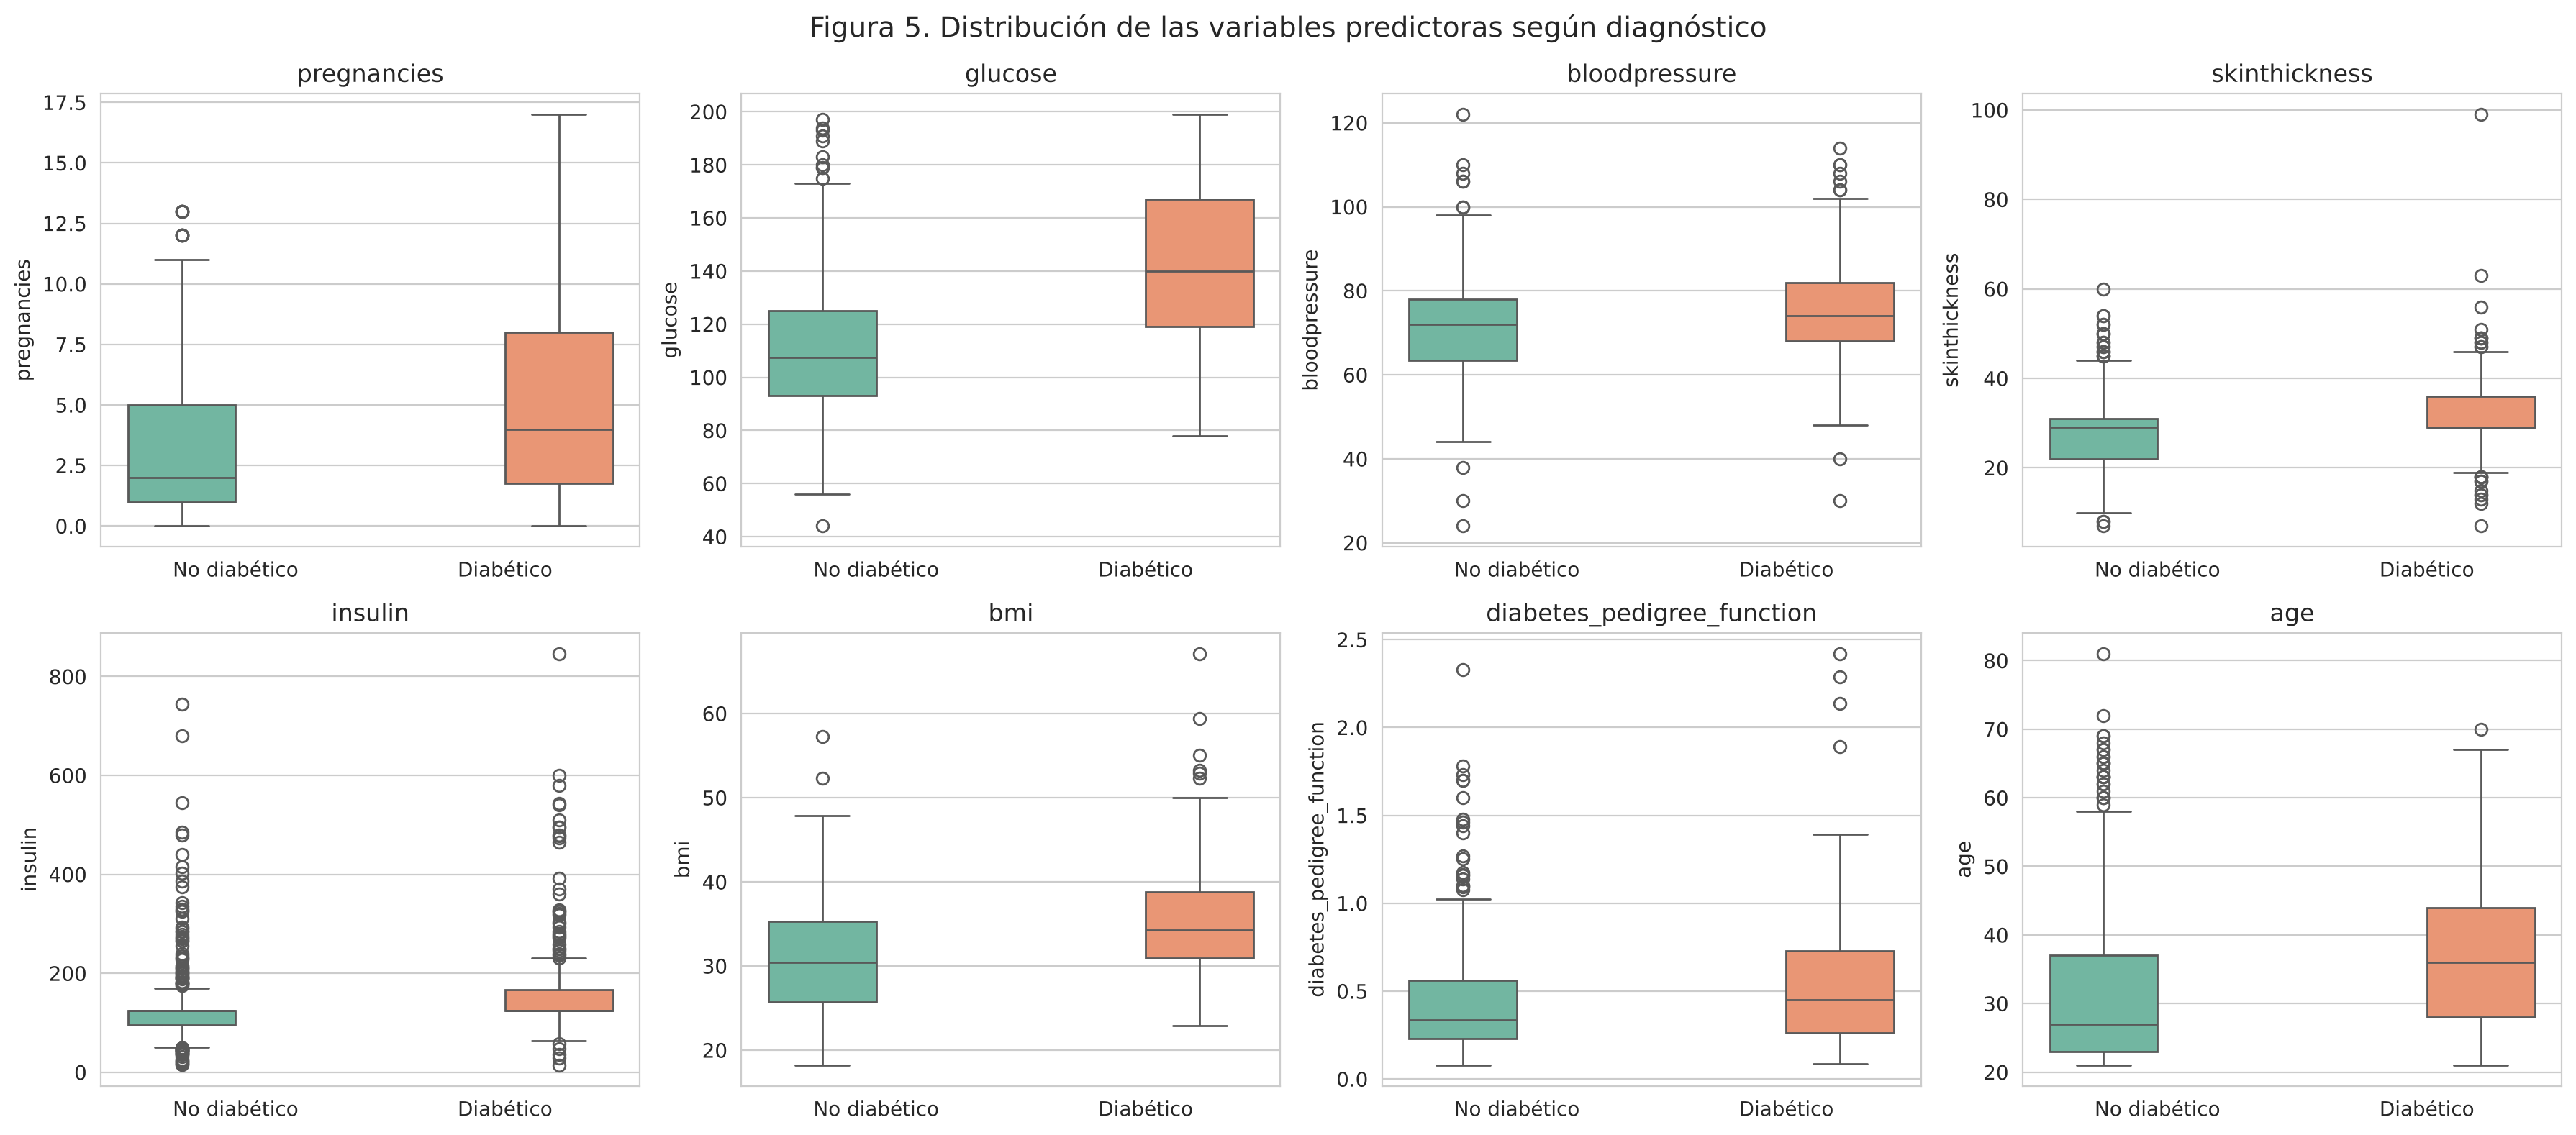

In [24]:
# Figura 5. Distribución de cada predictora por diagnóstico (boxplots)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), predictoras):
    sns.boxplot(data=df_clean, x="outcome_label", y=col, hue="outcome_label", palette="Set2", legend=False, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
fig.suptitle("Figura 5. Distribución de las variables predictoras según diagnóstico", fontsize=14)
plt.tight_layout()
plt.savefig("figs/viz5_boxplots_por_clase.png", dpi=100)
plt.show()

**Interpretación (Figura 5):** las cajas de `glucose`, `bmi` y `age` están claramente desplazadas hacia arriba en el grupo diabético, con poco solapamiento en el caso de la glucosa. En `insulin` y `skinthickness` muchos puntos se concentran en la mediana, efecto de la imputación de los ceros. `bloodpressure` presenta cajas muy similares en ambos grupos. Los outliers aparecen en las dos clases, por lo que no son exclusivos de un diagnóstico.

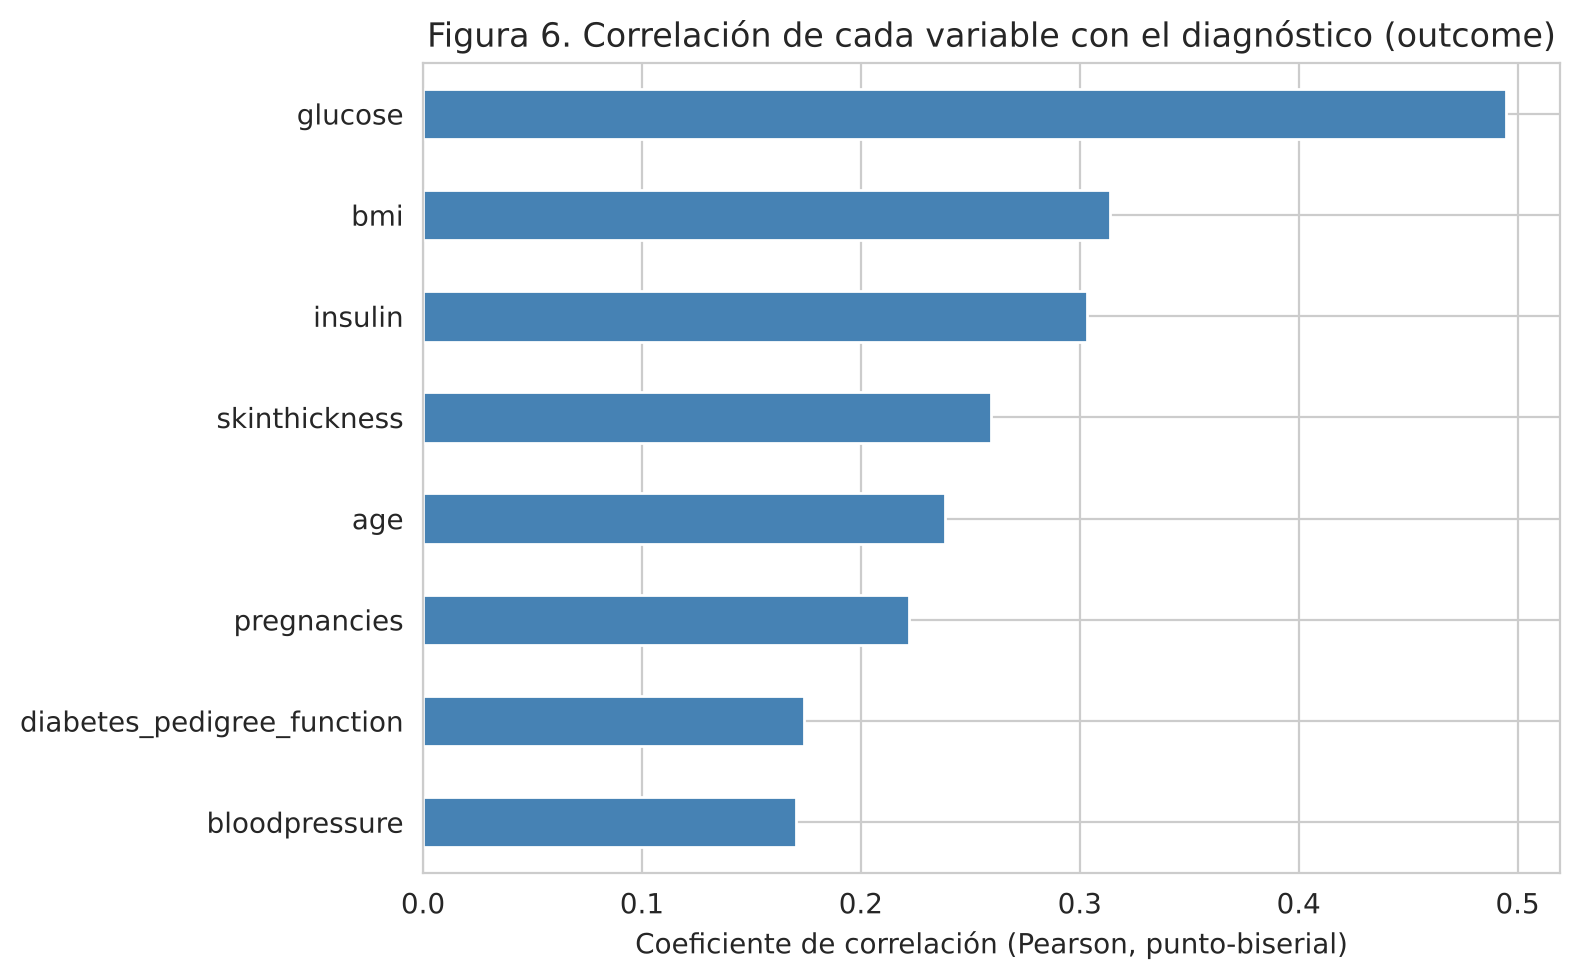

bloodpressure                 0.171
diabetes_pedigree_function    0.174
pregnancies                   0.222
age                           0.238
skinthickness                 0.259
insulin                       0.303
bmi                           0.314
glucose                       0.495
dtype: float64


In [25]:
# Figura 6. Correlación de cada predictora con la variable objetivo
corr_obj = df_model[predictoras].corrwith(df_model["outcome"]).sort_values()
plt.figure(figsize=(8, 5))
corr_obj.plot(kind="barh", color="steelblue")
plt.title("Figura 6. Correlación de cada variable con el diagnóstico (outcome)")
plt.xlabel("Coeficiente de correlación (Pearson, punto‑biserial)")
plt.tight_layout()
plt.savefig("figs/viz6_correlacion_objetivo.png", dpi=100)
plt.show()
print(corr_obj.round(3))

**Interpretación (Figura 6):** `glucose` es la variable con mayor asociación lineal con el diagnóstico (r ≈ 0.49), seguida de `bmi` (≈ 0.31) e `insulin` (≈ 0.30). `bloodpressure` (≈ 0.17) y `diabetes_pedigree_function` (≈ 0.17) son las de menor asociación. Ninguna correlación es suficientemente alta como para que una sola variable resuelva el problema, lo que justifica usar modelos multivariados.

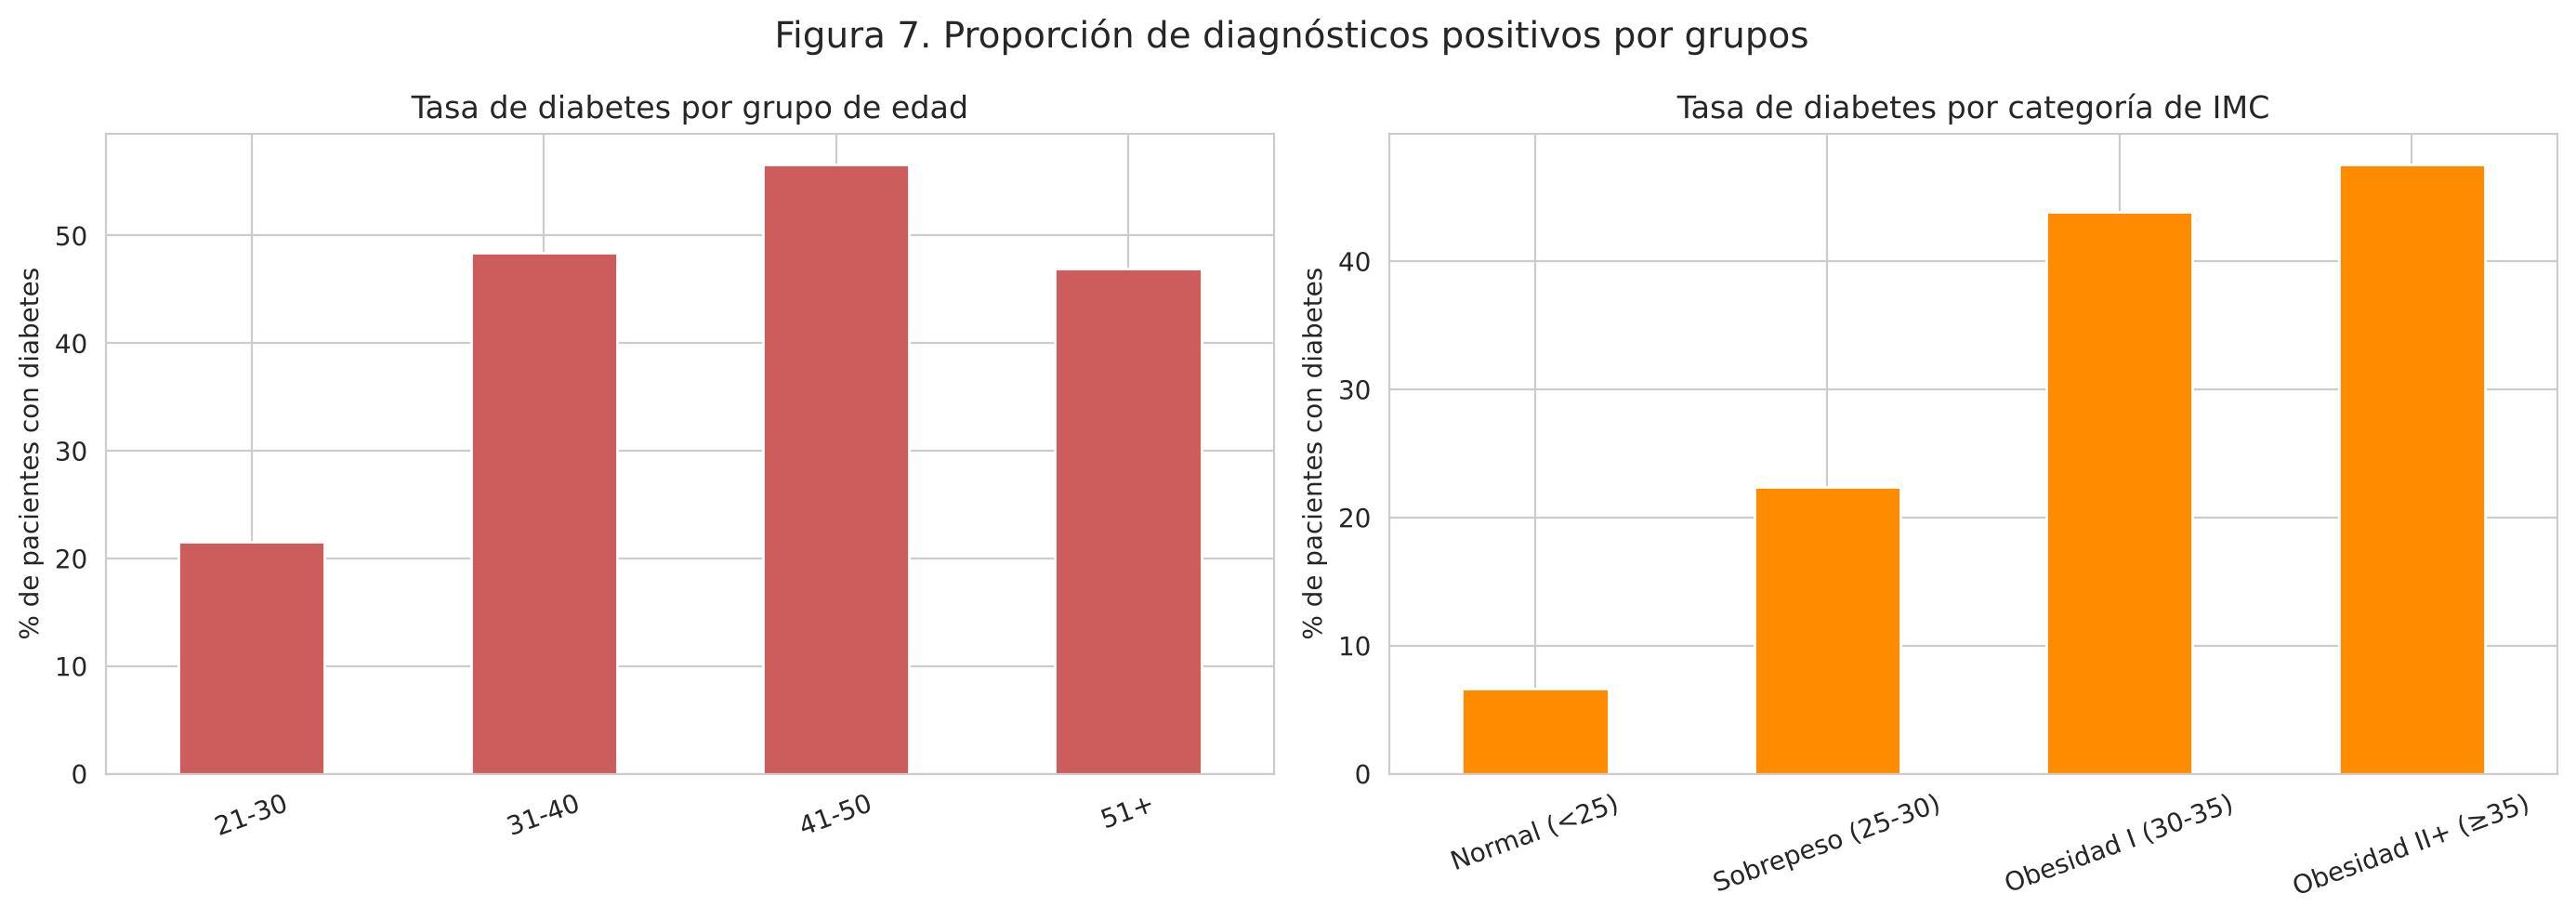

Tasa de diabetes (%) por grupo de edad:
grupo_edad
21-30    21.6
31-40    48.4
41-50    56.6
51+      46.9
Name: outcome_num, dtype: float64

Tasa de diabetes (%) por categoría de IMC:
categoria_imc
Normal (<25)           6.6
Sobrepeso (25-30)     22.3
Obesidad I (30-35)    43.8
Obesidad II+ (≥35)    47.6
Name: outcome_num, dtype: float64

Número de pacientes por grupo de edad:
grupo_edad
21-30    417
31-40    157
41-50    113
51+       81
Name: count, dtype: int64


In [26]:
# Figura 7. Tasa de diabetes por grupo de edad y por categoría de IMC
df_eda = df_clean.copy()
df_eda["outcome_num"] = df_eda["outcome"].astype(int)
df_eda["grupo_edad"] = pd.cut(df_eda["age"], bins=[20, 30, 40, 50, 90], labels=["21-30", "31-40", "41-50", "51+"])
df_eda["categoria_imc"] = pd.cut(df_eda["bmi"], bins=[0, 25, 30, 35, 100],
                                 labels=["Normal (<25)", "Sobrepeso (25-30)", "Obesidad I (30-35)", "Obesidad II+ (≥35)"], right=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tasa_edad = df_eda.groupby("grupo_edad", observed=True)["outcome_num"].mean() * 100
tasa_imc = df_eda.groupby("categoria_imc", observed=True)["outcome_num"].mean() * 100
tasa_edad.plot(kind="bar", ax=axes[0], color="indianred"); axes[0].set_title("Tasa de diabetes por grupo de edad")
tasa_imc.plot(kind="bar", ax=axes[1], color="darkorange"); axes[1].set_title("Tasa de diabetes por categoría de IMC")
for ax in axes:
    ax.set_ylabel("% de pacientes con diabetes"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
fig.suptitle("Figura 7. Proporción de diagnósticos positivos por grupos", fontsize=14)
plt.tight_layout()
plt.savefig("figs/viz7_tasas_grupos.png", dpi=100)
plt.show()

print("Tasa de diabetes (%) por grupo de edad:"); print(tasa_edad.round(1))
print("\nTasa de diabetes (%) por categoría de IMC:"); print(tasa_imc.round(1))
print("\nNúmero de pacientes por grupo de edad:"); print(df_eda["grupo_edad"].value_counts().sort_index())

**Interpretación (Figura 7):** la proporción de diagnósticos positivos pasa de 21.6 % en el grupo de 21–30 años a 56.6 % en el de 41–50 años, y baja a 46.9 % en el de 51+ (grupo con solo 81 registros, por lo que su tasa es menos estable). Por IMC, la tasa es de apenas 6.6 % con IMC normal y crece de forma sostenida hasta 47.6 % con obesidad grado II o más. Esto coincide con lo observado en la visualización edad vs. IMC de la sección 6.

**Decisiones de modelado derivadas del EDA:**
1. Se usarán **todas** las predictoras: aunque `bloodpressure` aporta poco, no hay razones para excluirla y los modelos pueden asignarle bajo peso.
2. El **desbalance** (65 % / 35 %) obliga a usar división **estratificada** y a no evaluar solo con accuracy: un modelo que predijera siempre "No diabético" tendría 65 % de accuracy sin detectar a ninguna paciente.
3. Como las variables tienen escalas muy distintas (`insulin` hasta 846, `diabetes_pedigree_function` hasta 2.4), se escalan los datos para la regresión logística.

## 9. Diseño de la evaluación, línea base y reproducción del avance 2

**Reglas definidas antes de comparar modelos** (para que ninguna decisión dependa del conjunto de prueba):

1. **Partición:** 80 % entrenamiento / 20 % prueba, estratificada por `outcome`, con `random_state=42`; es la misma del avance 2.
2. **Ajuste y selección:** validación cruzada estratificada de 5 particiones **dentro del entrenamiento**. El conjunto de prueba (154 registros) solo se usa para informar el desempeño final de cada modelo.
3. **Métrica de selección:** F1-score de la clase diabética (`1`) en validación cruzada. Equilibra recall y precision y no se deja engañar por el desbalance. Se reporta además el **recall** de la clase diabética, que es la métrica de mayor interés clínico: un falso negativo (paciente diabética clasificada como sana) retrasa el diagnóstico, mientras que un falso positivo solo lleva a una prueba de glucosa adicional. El accuracy no se usa para decidir.
4. **Regla de selección:** gana el modelo con mayor F1 medio en validación cruzada entre todos los evaluados (los del avance 2 con hiperparámetros por defecto y los ajustados).
5. **Umbral de decisión:** el que maximiza el F1 sobre probabilidades *fuera de muestra* del entrenamiento (sección 11).
6. **Línea base:** un clasificador que siempre predice la clase mayoritaria.

Todos los pasos de preparación (imputación, escalamiento, SMOTE) están **dentro del `Pipeline`**, por lo que se ajustan solo con los datos de entrenamiento de cada partición y no hay fuga de información.

In [27]:
import warnings, json
import joblib, sklearn
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.impute import KNNImputer
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore", category=FutureWarning)
print("scikit-learn", sklearn.__version__)

# 9.1 Partición (idéntica a la del avance 2)
X = df_model[predictoras]
y = df_model["outcome"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

dist = pd.DataFrame({
    "Registros": [len(y), len(y_train), len(y_test)],
    "Diabéticas (1)": [int(y.sum()), int(y_train.sum()), int(y_test.sum())],
    "No diabéticas (0)": [int((y == 0).sum()), int((y_train == 0).sum()), int((y_test == 0).sum())],
    "% diabéticas": [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
}, index=["Dataset completo", "Entrenamiento", "Prueba"]).round(1)
print("Tabla 2. Distribución final de la variable objetivo")
dist

scikit-learn 1.9.1
Tabla 2. Distribución final de la variable objetivo


,Registros,Diabéticas (1),No diabéticas (0),% diabéticas
Dataset completo,768,268,500,34.9
Entrenamiento,614,214,400,34.9
Prueba,154,54,100,35.1


In [28]:
# 9.2 Funciones de evaluación reutilizadas en todo el notebook
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}
NOMBRES_METRICAS = {"accuracy": "Accuracy", "precision": "Precision (1)", "recall": "Recall (1)",
                    "f1": "F1-score (1)", "roc_auc": "AUC-ROC"}

def crear_imputador():
    # Se crea un objeto nuevo en cada pipeline para que ningún modelo comparta estado con otro
    return SimpleImputer(strategy="median")

def evaluar_cv(pipe):
    # Validación cruzada sobre el ENTRENAMIENTO: devuelve media y desviación de cada métrica
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    return {m: (r[f"test_{m}"].mean(), r[f"test_{m}"].std()) for m in SCORING}

def metricas_prueba(pipe, umbral=0.5):
    # Desempeño en datos NO usados para entrenar, con el umbral indicado
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= umbral).astype(int)
    pred_tr = (pipe.predict_proba(X_train)[:, 1] >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "Accuracy entrenamiento": accuracy_score(y_train, pred_tr),
        "Accuracy prueba": accuracy_score(y_test, pred),
        "Precision (1)": precision_score(y_test, pred, zero_division=0),
        "Recall (1)": recall_score(y_test, pred),
        "F1-score (1)": f1_score(y_test, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, proba),
        "FP": int(fp), "FN": int(fn), "VP": int(tp), "VN": int(tn),
    }

# 9.3 Línea base y modelos del avance 2 (hiperparámetros por defecto)
modelos_base = {
    "Línea base (clase mayoritaria)": Pipeline([("modelo", DummyClassifier(strategy="most_frequent"))]),
    "Regresión logística": Pipeline([("imputador", crear_imputador()), ("escalador", StandardScaler()),
                                     ("modelo", LogisticRegression(max_iter=1000))]),
    "Regresión logística (balanceada)": Pipeline([("imputador", crear_imputador()), ("escalador", StandardScaler()),
                                                  ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Árbol de decisión": Pipeline([("imputador", crear_imputador()),
                                   ("modelo", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("imputador", crear_imputador()),
                               ("modelo", RandomForestClassifier(random_state=RANDOM_STATE))]),
}
for pipe in modelos_base.values():
    pipe.fit(X_train, y_train)

tabla_base = pd.DataFrame({n: metricas_prueba(p) for n, p in modelos_base.items()}).T
print("Tabla 3. Línea base y modelos del avance 2 re-ejecutados (prueba: 154 registros)")
tabla_base[["Accuracy entrenamiento", "Accuracy prueba", "Precision (1)", "Recall (1)",
            "F1-score (1)", "AUC-ROC"]].astype(float).round(3)

Tabla 3. Línea base y modelos del avance 2 re-ejecutados (prueba: 154 registros)


,Accuracy entrenamiento,Accuracy prueba,Precision (1),Recall (1),F1-score (1),AUC-ROC
Línea base (clase mayoritaria),0.651,0.649,0.000,0.000,0.000,0.500
Regresión logística,0.796,0.708,0.600,0.500,0.545,0.813
Regresión logística (balanceada),0.759,0.734,0.603,0.704,0.650,0.813
Árbol de decisión,1.000,0.682,0.553,0.481,0.515,0.636
Random Forest,1.000,0.766,0.696,0.593,0.640,0.821


In [29]:
# 9.4 Comprobación de continuidad: las cifras del avance 2 deben reproducirse exactamente
reportado_avance2 = {   # (accuracy prueba, recall, F1) publicados en el notebook del avance 2
    "Regresión logística": (0.708, 0.500, 0.545),
    "Regresión logística (balanceada)": (0.734, 0.704, 0.650),
    "Árbol de decisión": (0.682, 0.481, 0.515),
    "Random Forest": (0.766, 0.593, 0.640),
}
for nombre, (acc, rec, f1v) in reportado_avance2.items():
    fila = tabla_base.loc[nombre]
    ok = (round(fila["Accuracy prueba"], 3), round(fila["Recall (1)"], 3), round(fila["F1-score (1)"], 3)) == (acc, rec, f1v)
    print(f"{nombre:36s} coincide con el avance 2: {ok}")
    assert ok, f"No se reprodujo el resultado del avance 2 para {nombre}"

Regresión logística                  coincide con el avance 2: True
Regresión logística (balanceada)     coincide con el avance 2: True
Árbol de decisión                    coincide con el avance 2: True
Random Forest                        coincide con el avance 2: True


In [30]:
fila_dummy = tabla_base.loc["Línea base (clase mayoritaria)"]
display(Markdown(
    f"**Interpretación (Tabla 3).** La línea base obtiene un accuracy de **{fila_dummy['Accuracy prueba']:.3f}** sin detectar a "
    f"ninguna paciente diabética (recall {fila_dummy['Recall (1)']:.3f}, F1 {fila_dummy['F1-score (1)']:.3f}). Esto confirma que el accuracy por sí solo "
    f"no sirve para juzgar un modelo en este problema: cualquier modelo útil debe superar a la línea base en recall y F1, no solo en accuracy. "
    f"Los cuatro modelos del avance 2 se reprodujeron exactamente (verificación anterior), por lo que los resultados nuevos son comparables con los ya reportados."
))

**Interpretación (Tabla 3).** La línea base obtiene un accuracy de **0.649** sin detectar a ninguna paciente diabética (recall 0.000, F1 0.000). Esto confirma que el accuracy por sí solo no sirve para juzgar un modelo en este problema: cualquier modelo útil debe superar a la línea base en recall y F1, no solo en accuracy. Los cuatro modelos del avance 2 se reprodujeron exactamente (verificación anterior), por lo que los resultados nuevos son comparables con los ya reportados.

## 10. Ajuste de hiperparámetros y selección del modelo

Se ajusta, con `GridSearchCV` (5 particiones estratificadas, solo entrenamiento, `refit` por F1 de la clase diabética), una familia de modelos por técnica:

- **Regresión logística balanceada:** parámetro de regularización `C` (a menor `C`, más regularización).
- **Árbol de decisión balanceado:** profundidad máxima y tamaño mínimo de hoja. En el avance 2 el árbol sin límites tenía accuracy de 1,000 en entrenamiento (sobreajuste); estos parámetros lo restringen.
- **Random Forest balanceado:** número de árboles, profundidad máxima y tamaño mínimo de hoja.
- **Regresión logística + SMOTE:** el sobremuestreo sintético de la clase minoritaria se aplica **solo dentro de cada partición de entrenamiento** de la validación cruzada (nunca a datos de validación o prueba).

`class_weight="balanced"` se fija en los modelos que lo admiten porque el desbalance 65/35 y el mayor costo de un falso negativo ya se justificaron en el EDA; lo que se ajusta son los hiperparámetros de complejidad.

In [31]:
familias = {
    "Regresión logística balanceada (ajustada)": (
        Pipeline([("imputador", crear_imputador()), ("escalador", StandardScaler()),
                  ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
        {"modelo__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}),
    "Árbol de decisión balanceado (ajustado)": (
        Pipeline([("imputador", crear_imputador()),
                  ("modelo", DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"))]),
        {"modelo__max_depth": [2, 3, 4, 5, 6], "modelo__min_samples_leaf": [5, 10, 20]}),
    "Random Forest balanceado (ajustado)": (
        Pipeline([("imputador", crear_imputador()),
                  ("modelo", RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"))]),
        {"modelo__n_estimators": [200, 400], "modelo__max_depth": [3, 5, 8, None],
         "modelo__min_samples_leaf": [1, 5, 10]}),
    "Regresión logística + SMOTE (ajustada)": (
        ImbPipeline([("imputador", crear_imputador()), ("escalador", StandardScaler()),
                     ("smote", SMOTE(random_state=RANDOM_STATE)),
                     ("modelo", LogisticRegression(max_iter=1000))]),
        {"modelo__C": [0.01, 0.1, 1, 10]}),
}

busquedas = {}
for nombre, (pipe, malla) in familias.items():
    gs = GridSearchCV(pipe, malla, cv=cv, scoring=SCORING, refit="f1", n_jobs=-1)
    gs.fit(X_train, y_train)
    busquedas[nombre] = gs
    print(f"{nombre}\n   mejores hiperparámetros: {gs.best_params_}")

Regresión logística balanceada (ajustada)
   mejores hiperparámetros: {'modelo__C': 0.1}


Árbol de decisión balanceado (ajustado)
   mejores hiperparámetros: {'modelo__max_depth': 6, 'modelo__min_samples_leaf': 20}


Random Forest balanceado (ajustado)
   mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 10, 'modelo__n_estimators': 400}


Regresión logística + SMOTE (ajustada)
   mejores hiperparámetros: {'modelo__C': 10}


In [32]:
# Tabla 4. Validación cruzada (entrenamiento) de TODOS los modelos: por defecto y ajustados
filas = {}
for nombre, pipe in modelos_base.items():
    if nombre.startswith("Línea base"):
        continue
    filas[nombre + " [defecto]"] = evaluar_cv(clone(pipe))
for nombre, gs in busquedas.items():
    i = gs.best_index_
    filas[nombre] = {m: (gs.cv_results_[f"mean_test_{m}"][i], gs.cv_results_[f"std_test_{m}"][i]) for m in SCORING}

cv_num = pd.DataFrame({n: {f"{m}_media": v[m][0] for m in SCORING} | {f"{m}_std": v[m][1] for m in SCORING}
                       for n, v in filas.items()}).T
tabla_cv = pd.DataFrame({NOMBRES_METRICAS[m]: [f"{cv_num.loc[n, m + '_media']:.3f} ± {cv_num.loc[n, m + '_std']:.3f}" for n in cv_num.index]
                         for m in SCORING}, index=cv_num.index)
print("Tabla 4. Validación cruzada de 5 particiones sobre el entrenamiento (media ± desviación estándar)")
tabla_cv

Tabla 4. Validación cruzada de 5 particiones sobre el entrenamiento (media ± desviación estándar)


,Accuracy,Precision (1),Recall (1),F1-score (1),AUC-ROC
Regresión logística [defecto],0.788 ± 0.019,0.764 ± 0.060,0.575 ± 0.023,0.655 ± 0.024,0.843 ± 0.019
Regresión logística (balanceada) [defecto],0.762 ± 0.011,0.649 ± 0.026,0.701 ± 0.039,0.672 ± 0.013,0.844 ± 0.016
Árbol de decisión [defecto],0.673 ± 0.023,0.531 ± 0.037,0.580 ± 0.050,0.552 ± 0.027,0.651 ± 0.021
Random Forest [defecto],0.761 ± 0.019,0.690 ± 0.042,0.575 ± 0.038,0.626 ± 0.027,0.816 ± 0.022
Regresión logística balanceada (ajustada),0.767 ± 0.008,0.651 ± 0.020,0.720 ± 0.050,0.682 ± 0.017,0.845 ± 0.013
Árbol de decisión balanceado (ajustado),0.751 ± 0.014,0.617 ± 0.010,0.753 ± 0.079,0.676 ± 0.034,0.800 ± 0.011
Random Forest balanceado (ajustado),0.772 ± 0.015,0.648 ± 0.029,0.766 ± 0.021,0.701 ± 0.009,0.838 ± 0.022
Regresión logística + SMOTE (ajustada),0.774 ± 0.016,0.661 ± 0.030,0.724 ± 0.045,0.690 ± 0.022,0.843 ± 0.020


In [33]:
# Regla de selección (definida en la sección 9): mayor F1 medio en validación cruzada
nombre_modelo = cv_num["f1_media"].idxmax()
segundo = cv_num["f1_media"].drop(nombre_modelo).idxmax()
print("Modelo seleccionado:", nombre_modelo)
print(f"F1 medio en validación cruzada: {cv_num.loc[nombre_modelo, 'f1_media']:.3f} ± {cv_num.loc[nombre_modelo, 'f1_std']:.3f}")
print(f"Segundo mejor: {segundo} ({cv_num.loc[segundo, 'f1_media']:.3f} ± {cv_num.loc[segundo, 'f1_std']:.3f})")

# Modelo candidato SIN ajustar (hiperparámetros ya elegidos)
if nombre_modelo in busquedas:
    candidato = clone(busquedas[nombre_modelo].best_estimator_)
else:
    candidato = clone(modelos_base[nombre_modelo.replace(" [defecto]", "")])
print("Hiperparámetros ajustados:", busquedas[nombre_modelo].best_params_ if nombre_modelo in busquedas else "valores por defecto")

Modelo seleccionado: Random Forest balanceado (ajustado)
F1 medio en validación cruzada: 0.701 ± 0.009
Segundo mejor: Regresión logística + SMOTE (ajustada) (0.690 ± 0.022)
Hiperparámetros ajustados: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 10, 'modelo__n_estimators': 400}


In [34]:
diferencia = cv_num.loc[nombre_modelo, "f1_media"] - cv_num.loc[segundo, "f1_media"]
display(Markdown(
    f"**Interpretación (Tabla 4).** Con la regla definida de antemano, el modelo seleccionado es **{nombre_modelo}**, con F1 medio de "
    f"**{cv_num.loc[nombre_modelo, 'f1_media']:.3f}** y recall medio de **{cv_num.loc[nombre_modelo, 'recall_media']:.3f}** en validación cruzada. "
    f"Le sigue {segundo} con F1 de {cv_num.loc[segundo, 'f1_media']:.3f} (diferencia de {diferencia:.3f}). "
    f"Comparado con los modelos del avance 2 con hiperparámetros por defecto, el ajuste "
    f"{'mejoró' if cv_num.loc[nombre_modelo, 'f1_media'] > cv_num.loc['Regresión logística (balanceada) [defecto]', 'f1_media'] else 'no mejoró'} "
    f"el F1 de la regresión logística balanceada elegida entonces ({cv_num.loc['Regresión logística (balanceada) [defecto]', 'f1_media']:.3f}). "
    f"El árbol ajustado supera claramente al árbol sin límites ({cv_num.loc['Árbol de decisión balanceado (ajustado)', 'f1_media']:.3f} frente a "
    f"{cv_num.loc['Árbol de decisión [defecto]', 'f1_media']:.3f}), lo que confirma que su sobreajuste del avance 2 se debía a la falta de restricciones. "
    f"SMOTE alcanzó F1 de {cv_num.loc['Regresión logística + SMOTE (ajustada)', 'f1_media']:.3f}, frente a {cv_num.loc['Regresión logística balanceada (ajustada)', 'f1_media']:.3f} "
    f"de usar pesos de clase: ambas formas de tratar el desbalance rinden prácticamente igual en la regresión logística, por lo que no se justifica añadir SMOTE y su dependencia adicional al pipeline final. "
    f"Las diferencias entre modelos son pequeñas frente a la variabilidad entre particiones (desviaciones de hasta "
    f"{cv_num['f1_std'].max():.3f}), así que la selección debe leerse como una preferencia basada en evidencia moderada, no como una superioridad contundente."
))

**Interpretación (Tabla 4).** Con la regla definida de antemano, el modelo seleccionado es **Random Forest balanceado (ajustado)**, con F1 medio de **0.701** y recall medio de **0.766** en validación cruzada. Le sigue Regresión logística + SMOTE (ajustada) con F1 de 0.690 (diferencia de 0.011). Comparado con los modelos del avance 2 con hiperparámetros por defecto, el ajuste mejoró el F1 de la regresión logística balanceada elegida entonces (0.672). El árbol ajustado supera claramente al árbol sin límites (0.676 frente a 0.552), lo que confirma que su sobreajuste del avance 2 se debía a la falta de restricciones. SMOTE alcanzó F1 de 0.690, frente a 0.682 de usar pesos de clase: ambas formas de tratar el desbalance rinden prácticamente igual en la regresión logística, por lo que no se justifica añadir SMOTE y su dependencia adicional al pipeline final. Las diferencias entre modelos son pequeñas frente a la variabilidad entre particiones (desviaciones de hasta 0.034), así que la selección debe leerse como una preferencia basada en evidencia moderada, no como una superioridad contundente.

### 10.1 Comparación de imputadores

Se compara, con el modelo seleccionado y en validación cruzada, la imputación por **mediana** (usada hasta ahora), la mediana **con indicador de faltante** (agrega columnas que marcan qué valores estaban ausentes) y la imputación por **K vecinos (k = 5)**. Regla: se reemplaza la mediana solo si otro imputador mejora el F1 medio en más de una desviación estándar de la mediana; de lo contrario se conserva por simplicidad.

In [35]:
imputadores = {
    "Mediana": SimpleImputer(strategy="median"),
    "Mediana + indicador de faltante": SimpleImputer(strategy="median", add_indicator=True),
    "KNN (k = 5)": KNNImputer(n_neighbors=5),
}
res_imp = {}
for nombre_imp, imp in imputadores.items():
    p = clone(candidato)
    p.set_params(imputador=clone(imp))
    res_imp[nombre_imp] = evaluar_cv(p)

tabla_imp = pd.DataFrame({
    nombre_imp: {NOMBRES_METRICAS[m]: f"{v[m][0]:.3f} ± {v[m][1]:.3f}" for m in ["f1", "recall", "precision", "roc_auc"]}
    for nombre_imp, v in res_imp.items()}).T
print("Tabla 5. Comparación de imputadores en validación cruzada (modelo seleccionado)")
display(tabla_imp)

base_f1, base_sd = res_imp["Mediana"]["f1"]
mejor_imp = max(res_imp, key=lambda k: res_imp[k]["f1"][0])
imputador_final = mejor_imp if res_imp[mejor_imp]["f1"][0] - base_f1 > base_sd else "Mediana"
print("Imputador conservado:", imputador_final)
if mejor_imp == "Mediana":
    frase = (f"La mediana obtiene el mayor F1 medio ({base_f1:.3f}); el siguiente es "
             f"{max((k for k in res_imp if k != 'Mediana'), key=lambda k: res_imp[k]['f1'][0])} "
             f"({max(v['f1'][0] for k, v in res_imp.items() if k != 'Mediana'):.3f}). Se conserva **Mediana**.")
else:
    frase = (f"El mayor F1 medio lo obtiene **{mejor_imp}** ({res_imp[mejor_imp]['f1'][0]:.3f}) frente a {base_f1:.3f} de la mediana "
             f"(desviación {base_sd:.3f}). Como la diferencia {'supera' if imputador_final != 'Mediana' else 'no supera'} una desviación estándar, "
             f"se conserva **{imputador_final}**.")
display(Markdown(
    f"**Interpretación (Tabla 5).** {frase} Los tres imputadores rinden de forma muy parecida: con casi la mitad de la insulina ausente, "
    f"ningún método de imputación recupera información que el dato no contiene."
))

Tabla 5. Comparación de imputadores en validación cruzada (modelo seleccionado)


,F1-score (1),Recall (1),Precision (1),AUC-ROC
Mediana,0.701 ± 0.009,0.766 ± 0.021,0.648 ± 0.029,0.838 ± 0.022
Mediana + indicador de faltante,0.698 ± 0.006,0.766 ± 0.029,0.642 ± 0.025,0.836 ± 0.019
KNN (k = 5),0.692 ± 0.020,0.776 ± 0.018,0.625 ± 0.031,0.838 ± 0.019


Imputador conservado: Mediana


**Interpretación (Tabla 5).** La mediana obtiene el mayor F1 medio (0.701); el siguiente es Mediana + indicador de faltante (0.698). Se conserva **Mediana**. Los tres imputadores rinden de forma muy parecida: con casi la mitad de la insulina ausente, ningún método de imputación recupera información que el dato no contiene.

## 11. Umbral de decisión

Un clasificador probabilístico asigna "diabética" cuando la probabilidad estimada supera un umbral (0,5 por defecto). Para elegirlo sin usar el conjunto de prueba, se obtienen las probabilidades **fuera de muestra** del entrenamiento (cada paciente es predicha por un modelo que no la vio) y se evalúan varios umbrales. Según la regla de la sección 9, se escoge el que maximiza el F1.

Tabla 6. Umbral de decisión evaluado con probabilidades fuera de muestra del entrenamiento (n = 614)


,Recall (1),Precision (1),F1-score (1),Falsos negativos,Falsos positivos
Umbral,,,,,
0.25,0.953,0.459,0.620,10,240
0.30,0.930,0.491,0.643,15,206
0.35,0.888,0.522,0.657,24,174
0.40,0.869,0.579,0.695,28,135
0.45,0.799,0.600,0.685,43,114
0.50,0.766,0.646,0.701,50,90
0.55,0.696,0.674,0.685,65,72
0.60,0.603,0.701,0.648,85,55
0.65,0.519,0.735,0.608,103,40


Umbral seleccionado (máximo F1): 0.5


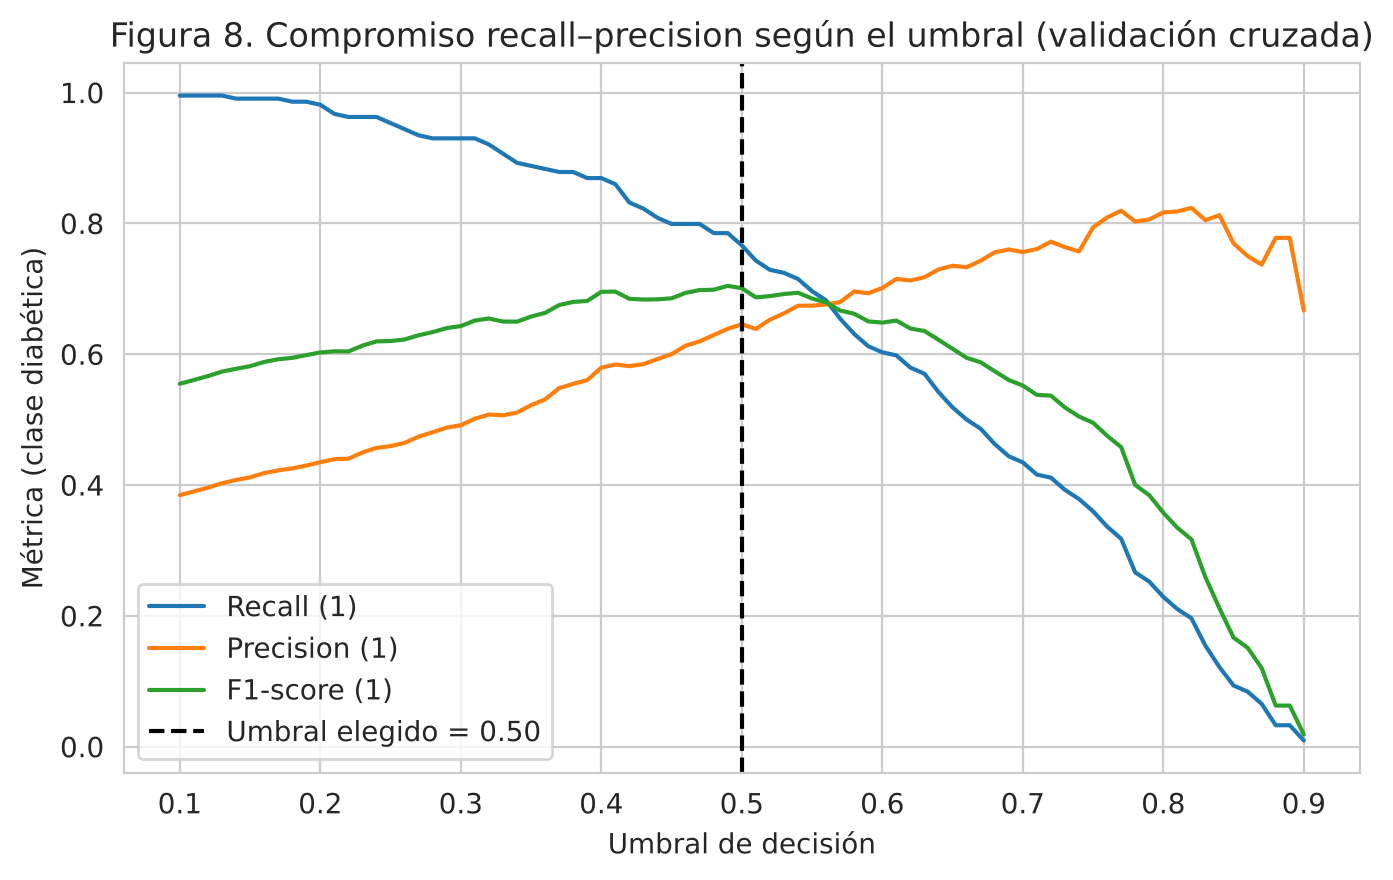

In [36]:
pipe_final = clone(candidato)
pipe_final.set_params(imputador=clone(imputadores[imputador_final]))

proba_oof = cross_val_predict(pipe_final, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

umbrales = np.round(np.arange(0.25, 0.651, 0.05), 2)
filas_u = []
for t in umbrales:
    p = (proba_oof >= t).astype(int)
    filas_u.append({"Umbral": t, "Recall (1)": recall_score(y_train, p), "Precision (1)": precision_score(y_train, p),
                    "F1-score (1)": f1_score(y_train, p), "Falsos negativos": int(((y_train == 1) & (p == 0)).sum()),
                    "Falsos positivos": int(((y_train == 0) & (p == 1)).sum())})
tabla_umbral = pd.DataFrame(filas_u).set_index("Umbral")
umbral_final = float(tabla_umbral["F1-score (1)"].idxmax())
print("Tabla 6. Umbral de decisión evaluado con probabilidades fuera de muestra del entrenamiento (n = %d)" % len(y_train))
display(tabla_umbral.round(3))
print("Umbral seleccionado (máximo F1):", umbral_final)

# Figura 8
grilla = np.arange(0.10, 0.91, 0.01)
curvas = pd.DataFrame({
    "Recall (1)": [recall_score(y_train, (proba_oof >= t).astype(int)) for t in grilla],
    "Precision (1)": [precision_score(y_train, (proba_oof >= t).astype(int), zero_division=0) for t in grilla],
    "F1-score (1)": [f1_score(y_train, (proba_oof >= t).astype(int), zero_division=0) for t in grilla]}, index=grilla)
ax = curvas.plot(figsize=(7, 4.5))
ax.axvline(umbral_final, color="k", ls="--", label=f"Umbral elegido = {umbral_final:.2f}")
ax.set_xlabel("Umbral de decisión"); ax.set_ylabel("Métrica (clase diabética)")
ax.set_title("Figura 8. Compromiso recall–precision según el umbral (validación cruzada)")
ax.legend(); plt.tight_layout(); plt.savefig("figs/viz8_umbral.png", dpi=100); plt.show()

In [37]:
t_alt = float(tabla_umbral.loc[tabla_umbral["Recall (1)"] >= 0.85, "F1-score (1)"].idxmax()) if (tabla_umbral["Recall (1)"] >= 0.85).any() else None
txt = (f"**Interpretación (Tabla 6 y Figura 8).** El F1 máximo se obtiene con un umbral de **{umbral_final:.2f}** "
       f"(recall {tabla_umbral.loc[umbral_final, 'Recall (1)']:.3f}, precision {tabla_umbral.loc[umbral_final, 'Precision (1)']:.3f}). "
       f"Bajar el umbral aumenta el recall a costa de más falsas alarmas: ")
if t_alt is not None:
    txt += (f"con {t_alt:.2f} el recall sube a {tabla_umbral.loc[t_alt, 'Recall (1)']:.3f} y la precision baja a {tabla_umbral.loc[t_alt, 'Precision (1)']:.3f}, "
            f"con un F1 de {tabla_umbral.loc[t_alt, 'F1-score (1)']:.3f}. ")
txt += ("Esta es una decisión de uso, no solo técnica: si el tamizaje prioriza no perder pacientes, un umbral menor puede ser preferible. "
        "Para esta entrega se conserva el umbral que maximiza F1 porque fue el criterio fijado antes de ver los resultados; "
        "el umbral alternativo queda documentado como opción de trabajo futuro.")
display(Markdown(txt))

**Interpretación (Tabla 6 y Figura 8).** El F1 máximo se obtiene con un umbral de **0.50** (recall 0.766, precision 0.646). Bajar el umbral aumenta el recall a costa de más falsas alarmas: con 0.40 el recall sube a 0.869 y la precision baja a 0.579, con un F1 de 0.695. Esta es una decisión de uso, no solo técnica: si el tamizaje prioriza no perder pacientes, un umbral menor puede ser preferible. Para esta entrega se conserva el umbral que maximiza F1 porque fue el criterio fijado antes de ver los resultados; el umbral alternativo queda documentado como opción de trabajo futuro.

## 12. Evaluación final sobre datos no utilizados para entrenar

Aquí, y solo aquí, se usa el conjunto de prueba. Se entrena el pipeline final con todo el conjunto de entrenamiento y se evalúa con el umbral elegido en la sección 11. Se comparan también la línea base y los demás modelos para dar contexto, sin que ninguno de esos resultados haya intervenido en la selección.

In [38]:
pipe_final.fit(X_train, y_train)

todos = {n: (p, 0.5) for n, p in modelos_base.items()}
todos |= {n + " [ajustado]" if "ajustad" not in n else n: (gs.best_estimator_, 0.5) for n, gs in busquedas.items()}
etiqueta_final = "★ MODELO FINAL: " + nombre_modelo + f" (umbral {umbral_final:.2f})"
todos[etiqueta_final] = (pipe_final, umbral_final)

tabla_final = pd.DataFrame({n: metricas_prueba(p, t) for n, (p, t) in todos.items()}).T
cols = ["Accuracy entrenamiento", "Accuracy prueba", "Precision (1)", "Recall (1)", "F1-score (1)", "AUC-ROC"]
print("Tabla 7. Desempeño en el conjunto de prueba (154 registros: 100 no diabéticas y 54 diabéticas)")
tabla_final[cols].astype(float).round(3)

Tabla 7. Desempeño en el conjunto de prueba (154 registros: 100 no diabéticas y 54 diabéticas)


,Accuracy entrenamiento,Accuracy prueba,Precision (1),Recall (1),F1-score (1),AUC-ROC
Línea base (clase mayoritaria),0.651,0.649,0.000,0.000,0.000,0.500
Regresión logística,0.796,0.708,0.600,0.500,0.545,0.813
Regresión logística (balanceada),0.759,0.734,0.603,0.704,0.650,0.813
Árbol de decisión,1.000,0.682,0.553,0.481,0.515,0.636
Random Forest,1.000,0.766,0.696,0.593,0.640,0.821
Regresión logística balanceada (ajustada),0.762,0.708,0.571,0.667,0.615,0.810
Árbol de decisión balanceado (ajustado),0.819,0.747,0.619,0.722,0.667,0.805
Random Forest balanceado (ajustado),0.832,0.734,0.594,0.759,0.667,0.820
Regresión logística + SMOTE (ajustada),0.757,0.714,0.581,0.667,0.621,0.811
★ MODELO FINAL: Random Forest balanceado (ajustado) (umbral 0.50),0.832,0.734,0.594,0.759,0.667,0.820


In [39]:
m = metricas_prueba(pipe_final, umbral_final)
pred_final = (pipe_final.predict_proba(X_test)[:, 1] >= umbral_final).astype(int)
print("Resultados por clase del modelo final (Tabla 8)")
print(classification_report(y_test, pred_final, target_names=["No diabético", "Diabético"], digits=3))

av2 = tabla_final.loc["Regresión logística (balanceada)"]
dummy = tabla_final.loc["Línea base (clase mayoritaria)"]
display(Markdown(
    f"**Interpretación (Tablas 7 y 8).** El modelo final alcanza en prueba un accuracy de **{m['Accuracy prueba']:.3f}**, precision **{m['Precision (1)']:.3f}**, "
    f"recall **{m['Recall (1)']:.3f}**, F1 **{m['F1-score (1)']:.3f}** y AUC-ROC **{m['AUC-ROC']:.3f}** para la clase diabética. "
    f"Frente a la línea base (recall {dummy['Recall (1)']:.3f}) detecta a {m['VP']} de las 54 pacientes diabéticas. "
    f"Frente al modelo elegido en el avance 2 (regresión logística balanceada con parámetros por defecto: recall {av2['Recall (1)']:.3f}, F1 {av2['F1-score (1)']:.3f}, "
    f"{int(av2['FN'])} falsos negativos), el modelo final obtiene recall {m['Recall (1)']:.3f}, F1 {m['F1-score (1)']:.3f} y {m['FN']} falsos negativos. "
    f"Esa diferencia es modesta y debe leerse con los intervalos de la Tabla 11: con solo 54 pacientes diabéticas en prueba, un solo caso cambia el recall en {100/54:.1f} puntos porcentuales."
))

Resultados por clase del modelo final (Tabla 8)
              precision    recall  f1-score   support

No diabético      0.847     0.720     0.778       100
   Diabético      0.594     0.759     0.667        54

    accuracy                          0.734       154
   macro avg      0.721     0.740     0.723       154
weighted avg      0.758     0.734     0.739       154



**Interpretación (Tablas 7 y 8).** El modelo final alcanza en prueba un accuracy de **0.734**, precision **0.594**, recall **0.759**, F1 **0.667** y AUC-ROC **0.820** para la clase diabética. Frente a la línea base (recall 0.000) detecta a 41 de las 54 pacientes diabéticas. Frente al modelo elegido en el avance 2 (regresión logística balanceada con parámetros por defecto: recall 0.704, F1 0.650, 16 falsos negativos), el modelo final obtiene recall 0.759, F1 0.667 y 13 falsos negativos. Esa diferencia es modesta y debe leerse con los intervalos de la Tabla 11: con solo 54 pacientes diabéticas en prueba, un solo caso cambia el recall en 1.9 puntos porcentuales.

### 12.1 Matrices de confusión

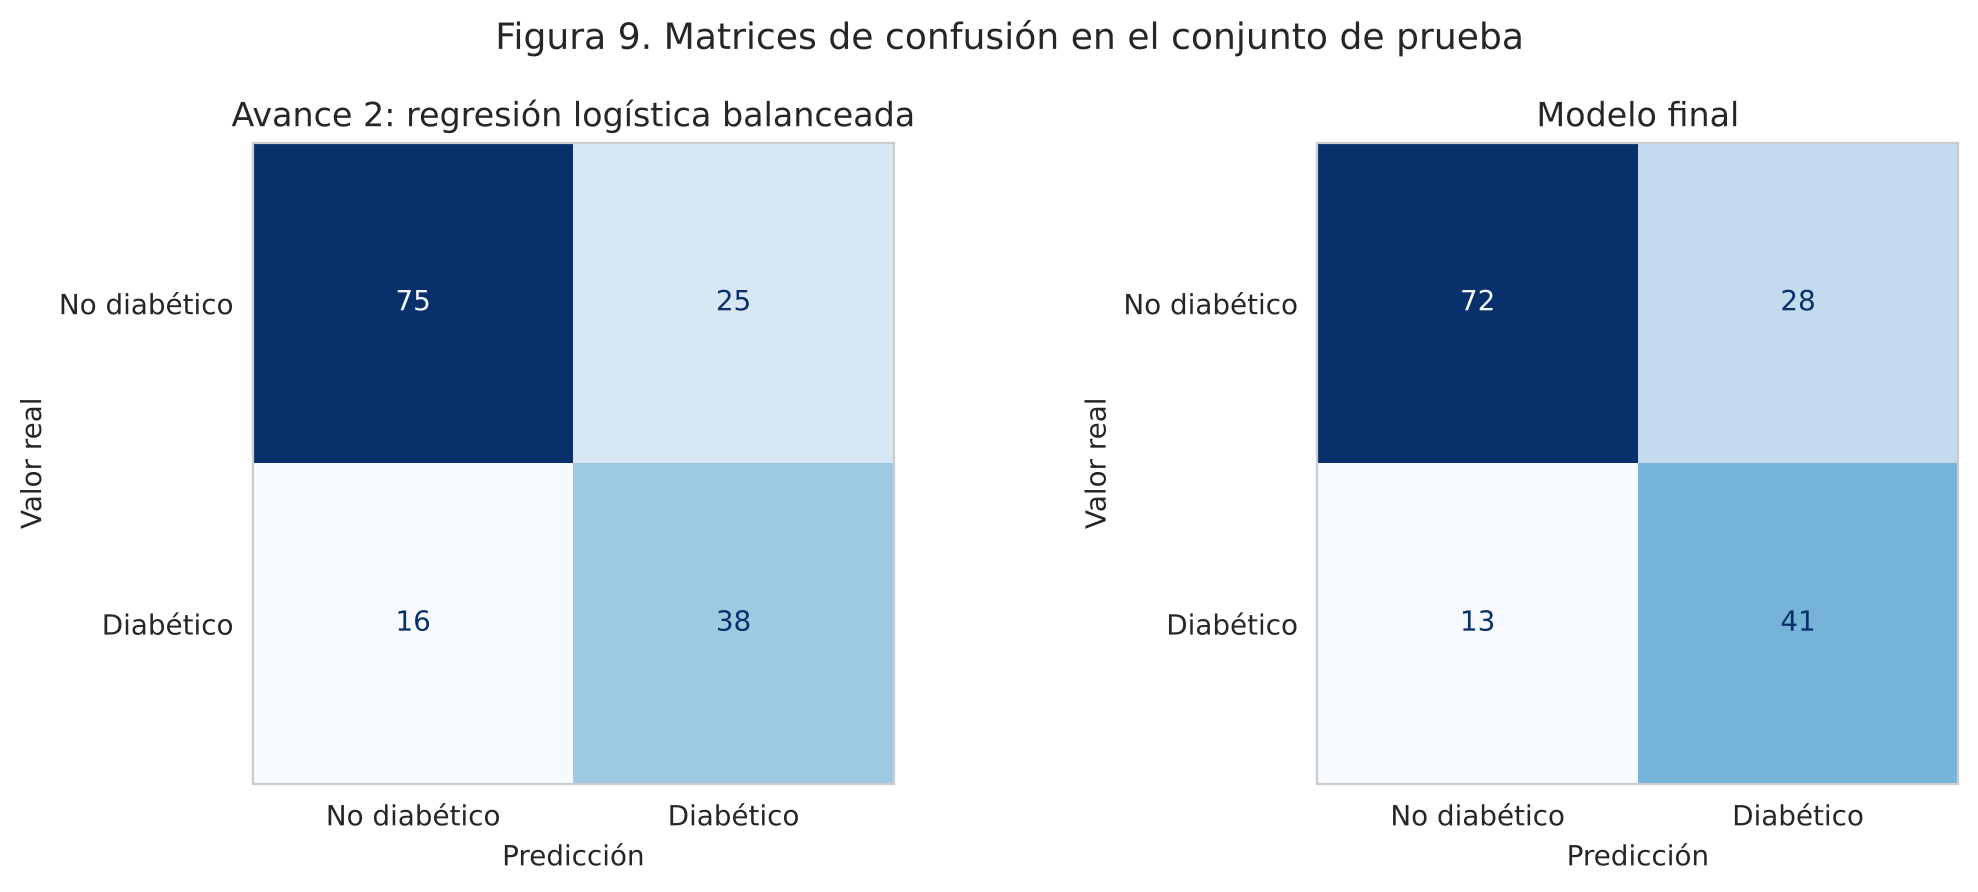

Tabla 9. Aciertos y errores en prueba


,VN,FP (falsa alarma),FN (diabética no detectada),VP
Regresión logística (balanceada),75,25,16,38
★ MODELO FINAL: Random Forest balanceado (ajustado) (umbral 0.50),72,28,13,41


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
comparados = [("Regresión logística (balanceada)", modelos_base["Regresión logística (balanceada)"], 0.5, "Avance 2: regresión logística balanceada"),
              (etiqueta_final, pipe_final, umbral_final, "Modelo final")]
for ax, (_, pipe, t, titulo) in zip(axes, comparados):
    p = (pipe.predict_proba(X_test)[:, 1] >= t).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=["No diabético", "Diabético"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(titulo); ax.grid(False); ax.set_xlabel("Predicción"); ax.set_ylabel("Valor real")
fig.suptitle("Figura 9. Matrices de confusión en el conjunto de prueba", fontsize=13)
plt.tight_layout(); plt.savefig("figs/viz9_matrices_confusion.png", dpi=100); plt.show()

tabla_err_global = tabla_final.loc[["Regresión logística (balanceada)", etiqueta_final], ["VN", "FP", "FN", "VP"]].astype(int)
tabla_err_global.columns = ["VN", "FP (falsa alarma)", "FN (diabética no detectada)", "VP"]
print("Tabla 9. Aciertos y errores en prueba")
tabla_err_global

In [41]:
display(Markdown(
    f"**Interpretación (Figura 9 y Tabla 9).** El error más costoso es el **falso negativo**: una paciente diabética clasificada como sana no sería remitida a exámenes confirmatorios. "
    f"El modelo final deja sin detectar **{m['FN']} de las 54** pacientes diabéticas ({m['FN'] / 54:.1%}) y genera **{m['FP']} falsas alarmas** entre las 100 no diabéticas ({m['FP'] / 100:.1%}). "
    f"El modelo del avance 2 dejaba sin detectar {int(av2['FN'])} y generaba {int(av2['FP'])} falsas alarmas. "
    f"Un falso positivo solo conduce a una prueba adicional de glucosa, de bajo costo; por eso se acepta una precision moderada ({m['Precision (1)']:.3f}) a cambio de un recall más alto."
))

**Interpretación (Figura 9 y Tabla 9).** El error más costoso es el **falso negativo**: una paciente diabética clasificada como sana no sería remitida a exámenes confirmatorios. El modelo final deja sin detectar **13 de las 54** pacientes diabéticas (24.1%) y genera **28 falsas alarmas** entre las 100 no diabéticas (28.0%). El modelo del avance 2 dejaba sin detectar 16 y generaba 25 falsas alarmas. Un falso positivo solo conduce a una prueba adicional de glucosa, de bajo costo; por eso se acepta una precision moderada (0.594) a cambio de un recall más alto.

### 12.2 Entrenamiento, validación cruzada y prueba

In [42]:
cv_final = cv_num.loc[nombre_modelo]
comp = pd.DataFrame({
    "Entrenamiento (reajustado)": [m["Accuracy entrenamiento"], np.nan, np.nan, np.nan],
    "Validación cruzada (entrenamiento)": [cv_final["accuracy_media"], cv_final["recall_media"], cv_final["f1_media"], cv_final["roc_auc_media"]],
    "Prueba": [m["Accuracy prueba"], m["Recall (1)"], m["F1-score (1)"], m["AUC-ROC"]],
}, index=["Accuracy", "Recall (1)", "F1-score (1)", "AUC-ROC"]).round(3)
print("Tabla 10. Comparación entre entrenamiento, validación cruzada y prueba (el umbral de la validación cruzada es 0,5)")
display(comp)

brecha_acc = m["Accuracy entrenamiento"] - m["Accuracy prueba"]
display(Markdown(
    f"**Interpretación.** La accuracy en entrenamiento ({m['Accuracy entrenamiento']:.3f}) supera a la de prueba ({m['Accuracy prueba']:.3f}) por {brecha_acc:.3f}: "
    f"hay cierto sobreajuste, pero mucho menor que el del avance 2 (Random Forest y árbol con accuracy de 1,000 en entrenamiento). "
    f"El F1 en validación cruzada ({cv_final['f1_media']:.3f}) y en prueba ({m['F1-score (1)']:.3f}) son del mismo orden; la diferencia de "
    f"{abs(cv_final['f1_media'] - m['F1-score (1)']):.3f} es compatible con la variabilidad de una partición de 154 registros "
    f"(desviación entre particiones de validación: {cv_final['f1_std']:.3f})."
))

Tabla 10. Comparación entre entrenamiento, validación cruzada y prueba (el umbral de la validación cruzada es 0,5)


,Entrenamiento (reajustado),Validación cruzada (entrenamiento),Prueba
Accuracy,0.832,0.772,0.734
Recall (1),NaN,0.766,0.759
F1-score (1),NaN,0.701,0.667
AUC-ROC,NaN,0.838,0.820


**Interpretación.** La accuracy en entrenamiento (0.832) supera a la de prueba (0.734) por 0.098: hay cierto sobreajuste, pero mucho menor que el del avance 2 (Random Forest y árbol con accuracy de 1,000 en entrenamiento). El F1 en validación cruzada (0.701) y en prueba (0.667) son del mismo orden; la diferencia de 0.034 es compatible con la variabilidad de una partición de 154 registros (desviación entre particiones de validación: 0.009).

### 12.3 Curvas ROC y variabilidad de las métricas

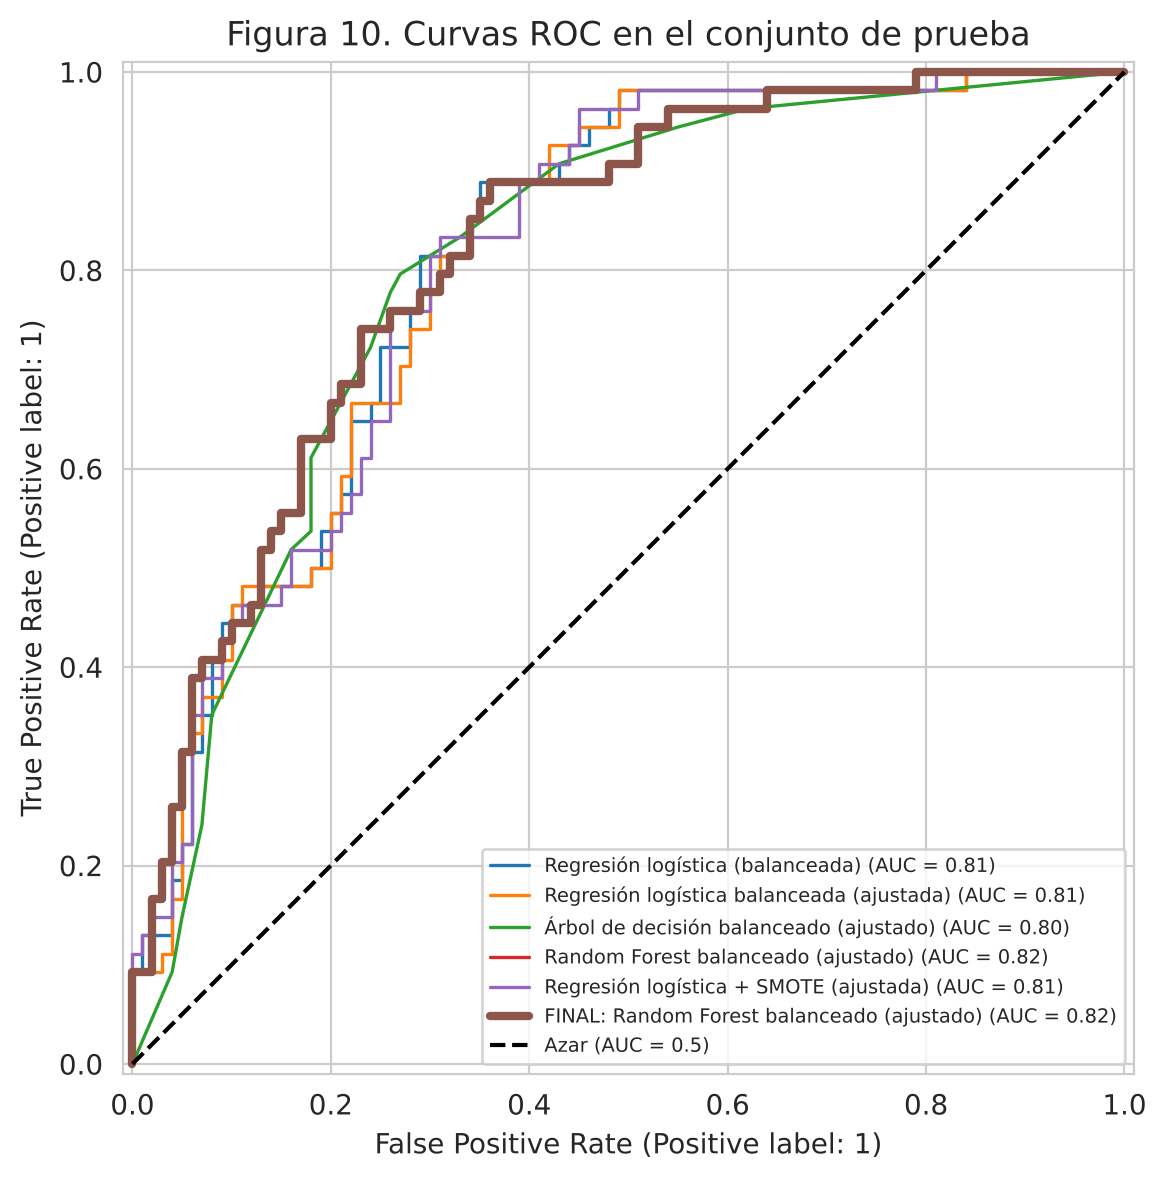

In [43]:
fig, ax = plt.subplots(figsize=(7, 6))
for nombre, (pipe, t) in todos.items():
    if nombre.startswith("Línea base") or nombre in ("Regresión logística", "Árbol de decisión", "Random Forest"):
        continue
    RocCurveDisplay.from_predictions(y_test, pipe.predict_proba(X_test)[:, 1],
                                     name=nombre.replace("★ MODELO FINAL: ", "FINAL: ").split(" (umbral")[0], ax=ax)
    ax.lines[-1].set_linewidth(3 if nombre == etiqueta_final else 1.2)
ax.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
ax.set_title("Figura 10. Curvas ROC en el conjunto de prueba")
ax.legend(loc="lower right", fontsize=7)
plt.tight_layout(); plt.savefig("figs/viz10_curvas_roc.png", dpi=100); plt.show()

In [44]:
# Intervalos bootstrap (2000 remuestreos del conjunto de prueba, semilla fija)
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy()
proba_f = pipe_final.predict_proba(X_test)[:, 1]
pred_f = (proba_f >= umbral_final).astype(int)
muestras = []
while len(muestras) < 2000:
    idx = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[idx])) < 2:
        continue
    muestras.append([accuracy_score(yt[idx], pred_f[idx]), precision_score(yt[idx], pred_f[idx], zero_division=0),
                     recall_score(yt[idx], pred_f[idx]), f1_score(yt[idx], pred_f[idx], zero_division=0),
                     roc_auc_score(yt[idx], proba_f[idx])])
muestras = np.array(muestras)
ic = pd.DataFrame({"Valor en prueba": [m["Accuracy prueba"], m["Precision (1)"], m["Recall (1)"], m["F1-score (1)"], m["AUC-ROC"]],
                   "IC 95 % inferior": np.percentile(muestras, 2.5, axis=0),
                   "IC 95 % superior": np.percentile(muestras, 97.5, axis=0)},
                  index=["Accuracy", "Precision (1)", "Recall (1)", "F1-score (1)", "AUC-ROC"]).round(3)
print("Tabla 11. Intervalos de confianza bootstrap del 95 % para el modelo final en prueba")
display(ic)
display(Markdown(
    f"**Interpretación (Figura 10 y Tabla 11).** El AUC-ROC del modelo final ({m['AUC-ROC']:.3f}) indica una capacidad moderada a buena de ordenar a las pacientes según su riesgo y es del mismo nivel que el de la regresión logística balanceada del avance 2. "
    f"Los intervalos son amplios: el recall en prueba ({m['Recall (1)']:.3f}) podría ubicarse entre {ic.loc['Recall (1)', 'IC 95 % inferior']:.3f} y {ic.loc['Recall (1)', 'IC 95 % superior']:.3f}, "
    f"y el F1 entre {ic.loc['F1-score (1)', 'IC 95 % inferior']:.3f} y {ic.loc['F1-score (1)', 'IC 95 % superior']:.3f}. "
    f"Por eso las diferencias de uno o dos puntos entre modelos no son concluyentes con este tamaño de muestra."
))

Tabla 11. Intervalos de confianza bootstrap del 95 % para el modelo final en prueba


,Valor en prueba,IC 95 % inferior,IC 95 % superior
Accuracy,0.734,0.669,0.799
Precision (1),0.594,0.475,0.708
Recall (1),0.759,0.646,0.870
F1-score (1),0.667,0.569,0.760
AUC-ROC,0.820,0.748,0.882


**Interpretación (Figura 10 y Tabla 11).** El AUC-ROC del modelo final (0.820) indica una capacidad moderada a buena de ordenar a las pacientes según su riesgo y es del mismo nivel que el de la regresión logística balanceada del avance 2. Los intervalos son amplios: el recall en prueba (0.759) podría ubicarse entre 0.646 y 0.870, y el F1 entre 0.569 y 0.760. Por eso las diferencias de uno o dos puntos entre modelos no son concluyentes con este tamaño de muestra.

## 13. Análisis de errores e importancia de las variables

In [45]:
grupo = np.select([(yt == 1) & (pred_f == 1), (yt == 1) & (pred_f == 0), (yt == 0) & (pred_f == 0), (yt == 0) & (pred_f == 1)],
                  ["VP (diabética detectada)", "FN (diabética no detectada)", "VN (sana, bien clasificada)", "FP (falsa alarma)"], default="")
err = X_test.copy()
err["grupo"] = grupo
tabla_err = err.groupby("grupo").agg(
    pacientes=("age", "size"), glucosa_mediana=("glucose", "median"), imc_mediana=("bmi", "median"),
    edad_mediana=("age", "median"), pct_insulina_faltante=("insulin", lambda s: s.isna().mean() * 100),
    pct_pliegue_faltante=("skinthickness", lambda s: s.isna().mean() * 100)).round(1)
print("Tabla 12. Perfil de los aciertos y errores del modelo final en prueba (valores observados, sin imputar)")
display(tabla_err)

fn, vp, vn, fp = (tabla_err.loc[k] for k in ["FN (diabética no detectada)", "VP (diabética detectada)", "VN (sana, bien clasificada)", "FP (falsa alarma)"])
display(Markdown(
    f"**Interpretación (Tabla 12).** Los falsos negativos tienen una glucosa mediana de **{fn['glucosa_mediana']:.0f} mg/dL**, "
    f"{'inferior' if fn['glucosa_mediana'] < vp['glucosa_mediana'] else 'superior'} a la de las diabéticas detectadas ({vp['glucosa_mediana']:.0f}) y "
    f"{'cercana' if abs(fn['glucosa_mediana'] - vn['glucosa_mediana']) < abs(fn['glucosa_mediana'] - vp['glucosa_mediana']) else 'más alejada'} a la de las sanas bien clasificadas ({vn['glucosa_mediana']:.0f}): "
    f"el modelo falla sobre todo en pacientes diabéticas cuyo perfil clínico se parece al de las no diabéticas. "
    f"Las falsas alarmas tienen glucosa mediana de {fp['glucosa_mediana']:.0f} mg/dL e IMC mediano de {fp['imc_mediana']:.1f}, "
    f"{'más cercanos a los de las diabéticas detectadas' if abs(fp['glucosa_mediana'] - vp['glucosa_mediana']) < abs(fp['glucosa_mediana'] - vn['glucosa_mediana']) else 'más cercanos a los de las sanas bien clasificadas'} "
    f"({vp['glucosa_mediana']:.0f} mg/dL e IMC {vp['imc_mediana']:.1f}) que a los del otro grupo: el modelo marca como riesgosos a perfiles que lo parecen aunque no tengan diagnóstico. "
    f"La proporción de pacientes con insulina ausente (imputada) es de {fn['pct_insulina_faltante']:.0f} % entre los falsos negativos y {vp['pct_insulina_faltante']:.0f} % entre las detectadas; "
    f"con grupos de {int(fn['pacientes'])} y {int(vp['pacientes'])} pacientes, esta comparación es solo orientativa y no permite concluir que la imputación cause los errores."
))

Tabla 12. Perfil de los aciertos y errores del modelo final en prueba (valores observados, sin imputar)


,pacientes,glucosa_mediana,imc_mediana,edad_mediana,pct_insulina_faltante,pct_pliegue_faltante
grupo,,,,,,
FN (diabética no detectada),13,114.0,31.0,28.0,61.5,46.2
FP (falsa alarma),28,138.0,35.1,32.0,53.6,28.6
"VN (sana, bien clasificada)",72,100.0,26.7,24.0,50.0,31.9
VP (diabética detectada),41,146.0,34.3,38.0,61.0,36.6


**Interpretación (Tabla 12).** Los falsos negativos tienen una glucosa mediana de **114 mg/dL**, inferior a la de las diabéticas detectadas (146) y cercana a la de las sanas bien clasificadas (100): el modelo falla sobre todo en pacientes diabéticas cuyo perfil clínico se parece al de las no diabéticas. Las falsas alarmas tienen glucosa mediana de 138 mg/dL e IMC mediano de 35.1, más cercanos a los de las diabéticas detectadas (146 mg/dL e IMC 34.3) que a los del otro grupo: el modelo marca como riesgosos a perfiles que lo parecen aunque no tengan diagnóstico. La proporción de pacientes con insulina ausente (imputada) es de 62 % entre los falsos negativos y 61 % entre las detectadas; con grupos de 13 y 41 pacientes, esta comparación es solo orientativa y no permite concluir que la imputación cause los errores.

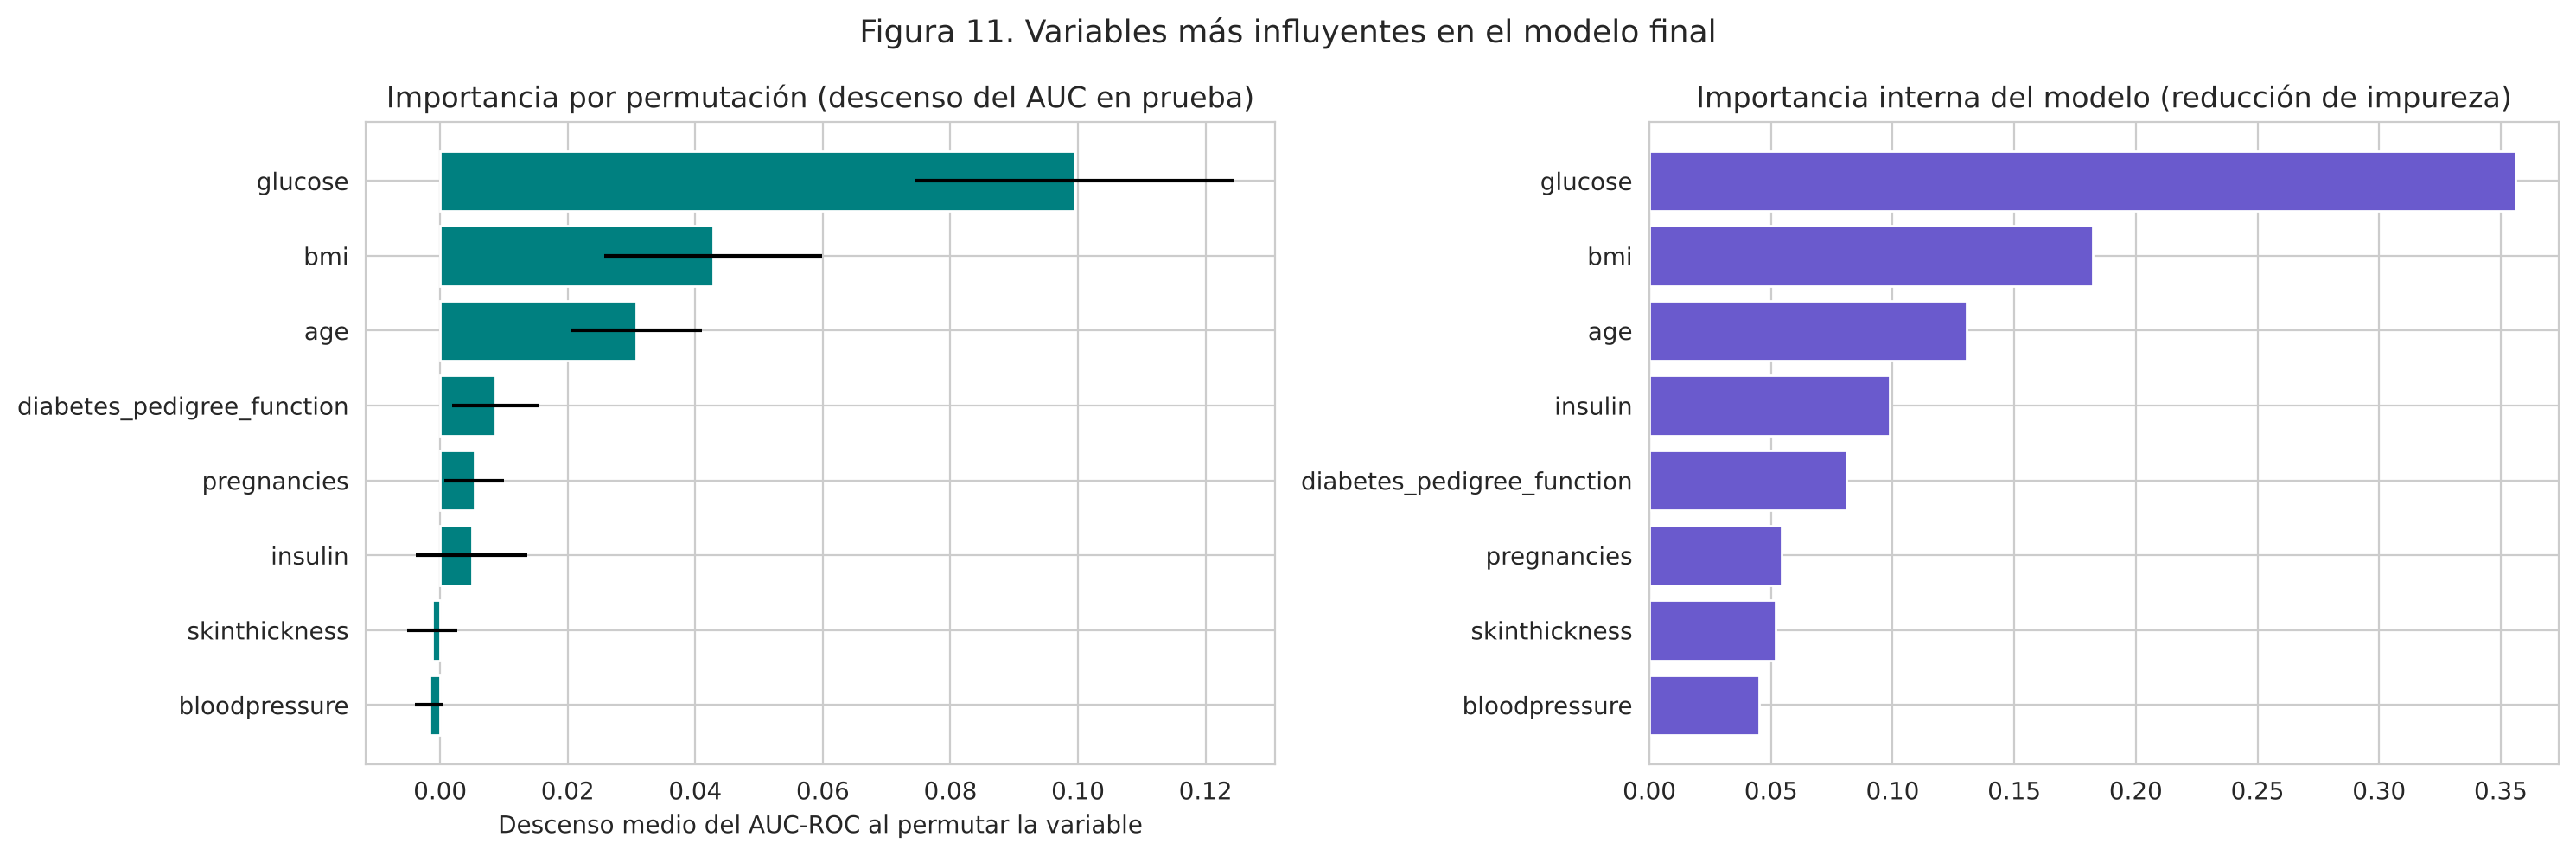

glucose                       0.0995
bmi                           0.0428
age                           0.0307
diabetes_pedigree_function    0.0087
pregnancies                   0.0053
insulin                       0.0050
skinthickness                -0.0013
bloodpressure                -0.0017
dtype: float64


**Interpretación (Figura 11).** La variable que más pesa es **glucose** (descenso de AUC de 0.099 al permutarla), seguida de **bmi** (0.043) y **age** (0.031). Esto coincide con el EDA (Figura 6), donde la glucosa y el IMC tenían la mayor asociación con el diagnóstico, y con el conocimiento clínico. Estas importancias describen qué usa el modelo para predecir, es decir asociaciones; no establecen que una variable cause la diabetes.

In [46]:
perm = permutation_importance(pipe_final, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=predictoras).sort_values()
err_perm = pd.Series(perm.importances_std, index=predictoras)[imp_perm.index]

modelo_interno = pipe_final.named_steps["modelo"]
paneles = 2 if hasattr(modelo_interno, "feature_importances_") else 1
fig, axes = plt.subplots(1, paneles, figsize=(7.5 * paneles, 5))
axes = np.atleast_1d(axes)
axes[0].barh(imp_perm.index, imp_perm.values, xerr=err_perm.values, color="teal")
axes[0].set_title("Importancia por permutación (descenso del AUC en prueba)")
axes[0].set_xlabel("Descenso medio del AUC-ROC al permutar la variable")
if paneles == 2:
    imp_int = pd.Series(modelo_interno.feature_importances_, index=predictoras).sort_values()
    axes[1].barh(imp_int.index, imp_int.values, color="slateblue")
    axes[1].set_title("Importancia interna del modelo (reducción de impureza)")
fig.suptitle("Figura 11. Variables más influyentes en el modelo final", fontsize=13)
plt.tight_layout(); plt.savefig("figs/viz11_importancia_variables.png", dpi=100); plt.show()
print(imp_perm.sort_values(ascending=False).round(4))

top = imp_perm.sort_values(ascending=False)
display(Markdown(
    f"**Interpretación (Figura 11).** La variable que más pesa es **{top.index[0]}** (descenso de AUC de {top.iloc[0]:.3f} al permutarla), seguida de **{top.index[1]}** ({top.iloc[1]:.3f}) y **{top.index[2]}** ({top.iloc[2]:.3f}). "
    f"Esto coincide con el EDA (Figura 6), donde la glucosa y el IMC tenían la mayor asociación con el diagnóstico, y con el conocimiento clínico. "
    f"Estas importancias describen qué usa el modelo para predecir, es decir asociaciones; no establecen que una variable cause la diabetes."
))

## 14. Modelo exportado para la aplicación de Streamlit

Se guarda en `modelo_diabetes.joblib` el **mismo objeto `Pipeline` ya entrenado y evaluado** en este notebook (imputación + modelo), junto con el umbral, la lista ordenada de variables que espera y los rangos observados en el entrenamiento (que la aplicación usa para advertir sobre valores atípicos). La aplicación no entrena ni transforma nada por su cuenta: llama a `pipeline.predict_proba` con las mismas ocho columnas.

In [47]:
rangos = {c: (float(X_train[c].min()), float(X_train[c].max())) for c in predictoras}
medianas_train = {c: float(X_train[c].median()) for c in predictoras}
artefacto = {
    "pipeline": pipe_final,
    "umbral": umbral_final,
    "variables": predictoras,
    "rangos_entrenamiento": rangos,
    "medianas_entrenamiento": medianas_train,
    "nombre_modelo": nombre_modelo,
    "version_scikit_learn": sklearn.__version__,
    "metricas_prueba": {k: (float(v) if not isinstance(v, (int, np.integer)) else int(v)) for k, v in m.items()},
    "ic95_prueba": {k: [float(ic.loc[k, "IC 95 % inferior"]), float(ic.loc[k, "IC 95 % superior"])] for k in ic.index},
}
joblib.dump(artefacto, "modelo_diabetes.joblib")

# Verificación: el objeto recargado produce exactamente las mismas probabilidades que el evaluado
recargado = joblib.load("modelo_diabetes.joblib")
p_orig = pipe_final.predict_proba(X_test)[:, 1]
p_recarg = recargado["pipeline"].predict_proba(X_test[recargado["variables"]])[:, 1]
assert np.allclose(p_orig, p_recarg), "El modelo recargado difiere del evaluado"
assert (((p_recarg >= recargado["umbral"]).astype(int)) == pred_final).all()
print("Modelo guardado y verificado: predicciones idénticas tras recargarlo (154 registros de prueba).")
print("Variables que espera el pipeline:", recargado["variables"])
print("Umbral:", recargado["umbral"], "| scikit-learn:", recargado["version_scikit_learn"])

Modelo guardado y verificado: predicciones idénticas tras recargarlo (154 registros de prueba).
Variables que espera el pipeline: ['pregnancies', 'glucose', 'bloodpressure', 'skinthickness', 'insulin', 'bmi', 'diabetes_pedigree_function', 'age']
Umbral: 0.5 | scikit-learn: 1.9.1


In [48]:
# Registros de referencia para comparar notebook y aplicación (misma entrada -> misma salida)
sel = {
    "Perfil con diabetes detectada (VP)": X_test.index[(yt == 1) & (pred_f == 1)][0],
    "Perfil sin diabetes bien clasificado (VN)": X_test.index[(yt == 0) & (pred_f == 0)][0],
    "Perfil con insulina y pliegue ausentes": X_test.index[X_test["insulin"].isna() & X_test["skinthickness"].isna()][0],
}
casos = X_test.loc[list(sel.values())].copy()
casos.insert(0, "caso", list(sel.keys()))
casos["indice_original"] = list(sel.values())
casos["probabilidad_notebook"] = pipe_final.predict_proba(casos[predictoras])[:, 1]
casos["clase_notebook"] = (casos["probabilidad_notebook"] >= umbral_final).astype(int)
casos["valor_real"] = y_test.loc[list(sel.values())].to_numpy()
casos.to_csv("casos_referencia.csv", index=False)
print("Tabla 13. Registros de referencia (se vuelven a ejecutar en Streamlit en test_app.py)")
casos.round(4)

Tabla 13. Registros de referencia (se vuelven a ejecutar en Streamlit en test_app.py)


,caso,pregnancies,glucose,bloodpressure,skinthickness,insulin,bmi,diabetes_pedigree_function,age,indice_original,probabilidad_notebook,clase_notebook,valor_real
387,Perfil con diabetes detectada (VP),8,105.0,100.0,36.0,NaN,43.3,0.239,45,387,0.5751,1,1
672,Perfil sin diabetes bien clasificado (VN),10,68.0,106.0,23.0,49.0,35.5,0.285,47,672,0.2847,0,0
44,Perfil con insulina y pliegue ausentes,7,159.0,64.0,NaN,NaN,27.4,0.294,40,44,0.6776,1,0


## 15. Discusión

In [49]:
f1_test = m["F1-score (1)"]
display(Markdown(f"""
**Qué significan los resultados.** Con los ocho indicadores clínicos disponibles, el modelo final identifica a **{m['VP']} de las 54** pacientes diabéticas del conjunto de prueba, con {m['FP']} falsas alarmas entre 100 pacientes sanas. Es una capacidad útil para *priorizar* quién debería hacerse una prueba confirmatoria, pero no para *diagnosticar*: el AUC-ROC de {m['AUC-ROC']:.3f} y una precision de {m['Precision (1)']:.3f} implican que alrededor de {100 * (1 - m['Precision (1)']):.0f} de cada 100 alertas serían falsas, y que se pierden {m['FN'] / 54:.0%} de las pacientes diabéticas.

**Relación con los antecedentes.** Dubey et al. (2021) estudiaron la predicción de diabetes con regresión logística, Naive Bayes, máquinas de soporte vectorial y Random Forest; en este proyecto se compararon regresión logística, árbol de decisión y Random Forest sobre el mismo tipo de problema, y los modelos de mejor desempeño fueron de la misma familia usada en ese antecedente. Las cifras no se comparan directamente porque dependen de la partición, del tratamiento de los valores faltantes y de la métrica elegida; aquí se evitó la fuga de información imputando dentro del `Pipeline`, lo que tiende a producir resultados más conservadores que los de flujos que imputan antes de dividir los datos.

**Por qué este modelo.** Se seleccionó con una regla fijada antes de comparar (mayor F1 en validación cruzada), no por su accuracy ni por su resultado en prueba: **{nombre_modelo}**. Su F1 en validación cruzada ({cv_final['f1_media']:.3f}) superó al de la regresión logística balanceada del avance 2 ({cv_num.loc['Regresión logística (balanceada) [defecto]', 'f1_media']:.3f}), aunque en prueba la diferencia es pequeña y sus intervalos bootstrap se solapan ampliamente. La decisión debe leerse como razonable y reproducible, no como la única defendible: la regresión logística ofrece interpretabilidad directa de coeficientes con un desempeño comparable.

**Errores, sesgos y limitaciones que permanecen.**
- El conjunto de prueba es pequeño (154 registros, 54 diabéticas); las métricas cambiarían con otra partición.
- `Insulin` tiene 48,7 % de valores ausentes y `SkinThickness` 29,6 %; la imputación por mediana reduce su variabilidad y su aporte debe interpretarse con cautela.
- El dataset contiene solo mujeres de ascendencia Pima de 21 años o más (Arizona, EE. UU.), por lo que los resultados **no son generalizables** a hombres, menores de edad ni otras poblaciones.
- Se usó una única fuente de datos y no hay validación externa.
- Las importancias de variables y las tasas por grupo describen asociaciones, no causas.

**Implicaciones técnicas, éticas y de uso.** La aplicación es un ejercicio académico: sus resultados no sustituyen una valoración profesional y no deben usarse para decidir sobre la salud de una persona. Un falso negativo puede dar una falsa tranquilidad, por lo que cualquier uso real exigiría un umbral más sensible, validación en la población objetivo y supervisión clínica.
"""))


**Qué significan los resultados.** Con los ocho indicadores clínicos disponibles, el modelo final identifica a **41 de las 54** pacientes diabéticas del conjunto de prueba, con 28 falsas alarmas entre 100 pacientes sanas. Es una capacidad útil para *priorizar* quién debería hacerse una prueba confirmatoria, pero no para *diagnosticar*: el AUC-ROC de 0.820 y una precision de 0.594 implican que alrededor de 41 de cada 100 alertas serían falsas, y que se pierden 24% de las pacientes diabéticas.

**Relación con los antecedentes.** Dubey et al. (2021) estudiaron la predicción de diabetes con regresión logística, Naive Bayes, máquinas de soporte vectorial y Random Forest; en este proyecto se compararon regresión logística, árbol de decisión y Random Forest sobre el mismo tipo de problema, y los modelos de mejor desempeño fueron de la misma familia usada en ese antecedente. Las cifras no se comparan directamente porque dependen de la partición, del tratamiento de los valores faltantes y de la métrica elegida; aquí se evitó la fuga de información imputando dentro del `Pipeline`, lo que tiende a producir resultados más conservadores que los de flujos que imputan antes de dividir los datos.

**Por qué este modelo.** Se seleccionó con una regla fijada antes de comparar (mayor F1 en validación cruzada), no por su accuracy ni por su resultado en prueba: **Random Forest balanceado (ajustado)**. Su F1 en validación cruzada (0.701) superó al de la regresión logística balanceada del avance 2 (0.672), aunque en prueba la diferencia es pequeña y sus intervalos bootstrap se solapan ampliamente. La decisión debe leerse como razonable y reproducible, no como la única defendible: la regresión logística ofrece interpretabilidad directa de coeficientes con un desempeño comparable.

**Errores, sesgos y limitaciones que permanecen.**
- El conjunto de prueba es pequeño (154 registros, 54 diabéticas); las métricas cambiarían con otra partición.
- `Insulin` tiene 48,7 % de valores ausentes y `SkinThickness` 29,6 %; la imputación por mediana reduce su variabilidad y su aporte debe interpretarse con cautela.
- El dataset contiene solo mujeres de ascendencia Pima de 21 años o más (Arizona, EE. UU.), por lo que los resultados **no son generalizables** a hombres, menores de edad ni otras poblaciones.
- Se usó una única fuente de datos y no hay validación externa.
- Las importancias de variables y las tasas por grupo describen asociaciones, no causas.

**Implicaciones técnicas, éticas y de uso.** La aplicación es un ejercicio académico: sus resultados no sustituyen una valoración profesional y no deben usarse para decidir sobre la salud de una persona. Un falso negativo puede dar una falsa tranquilidad, por lo que cualquier uso real exigiría un umbral más sensible, validación en la población objetivo y supervisión clínica.


## 16. Conclusiones y trabajo futuro

In [50]:
revision = (f"La métrica de selección (F1 de la clase diabética) quedó en {f1_test:.3f} en prueba, por debajo de 0,70; por eso se documenta la revisión realizada: "
            f"EDA dirigido a las variables y a la calidad de los datos, corrección de la fuga de información en la imputación, pesos de clase y SMOTE para el desbalance, "
            f"ajuste de hiperparámetros solo con validación cruzada, comparación de imputadores y estudio del umbral. "
            f"Ninguno de esos pasos se eligió para subir artificialmente la métrica en prueba; el resultado se mantiene tal como salió."
            ) if f1_test < 0.70 else (f"El F1 de la clase diabética en prueba ({f1_test:.3f}) alcanza el 0,70.")
display(Markdown(f"""
**Hallazgos del EDA y del modelado.** La glucosa es la variable más asociada al diagnóstico (r ≈ 0,49), seguida del IMC, la insulina y la edad; la tasa de diabetes crece con el IMC y con la edad. Existe un desbalance 65/35 y dos variables con muchos valores faltantes codificados como 0. En el modelado, la línea base alcanza {dummy['Accuracy prueba']:.3f} de accuracy sin detectar a ninguna paciente, y todos los modelos ajustados la superan en recall y F1.

**Desempeño y utilidad.** El modelo final (**{nombre_modelo}**, umbral {umbral_final:.2f}) obtiene en prueba recall {m['Recall (1)']:.3f} (IC 95 %: {ic.loc['Recall (1)', 'IC 95 % inferior']:.3f}–{ic.loc['Recall (1)', 'IC 95 % superior']:.3f}), precision {m['Precision (1)']:.3f}, F1 {f1_test:.3f}, accuracy {m['Accuracy prueba']:.3f} y AUC-ROC {m['AUC-ROC']:.3f}. Sirve como apoyo académico para priorizar pacientes que requieren una prueba confirmatoria, no como herramienta diagnóstica.

**Revisión del rendimiento.** {revision}

**Pruebas de la aplicación.** La aplicación `app.py` carga `modelo_diabetes.joblib`, es decir, el pipeline evaluado en este notebook. Los casos de prueba y su resultado están en `PRUEBAS.md` (con capturas en `capturas/`) y se re-ejecutan con `pytest test_app.py`; allí se verifica que los registros de referencia de la Tabla 13 producen la misma probabilidad en el notebook y en Streamlit. La prueba de acceso público debe realizarse después de desplegar la aplicación.

**Limitaciones.** Conjunto de prueba pequeño, alta proporción de insulina imputada, población única (mujeres Pima ≥ 21 años) y ausencia de validación externa (ver sección 15).

**Trabajo futuro.** Validar con un conjunto externo; evaluar el umbral más sensible de la Tabla 6 con un criterio clínico explícito; probar modelos de aumento de gradiente y calibración de probabilidades; y repetir la validación cruzada con repeticiones para estimar mejor la variabilidad.
"""))


**Hallazgos del EDA y del modelado.** La glucosa es la variable más asociada al diagnóstico (r ≈ 0,49), seguida del IMC, la insulina y la edad; la tasa de diabetes crece con el IMC y con la edad. Existe un desbalance 65/35 y dos variables con muchos valores faltantes codificados como 0. En el modelado, la línea base alcanza 0.649 de accuracy sin detectar a ninguna paciente, y todos los modelos ajustados la superan en recall y F1.

**Desempeño y utilidad.** El modelo final (**Random Forest balanceado (ajustado)**, umbral 0.50) obtiene en prueba recall 0.759 (IC 95 %: 0.646–0.870), precision 0.594, F1 0.667, accuracy 0.734 y AUC-ROC 0.820. Sirve como apoyo académico para priorizar pacientes que requieren una prueba confirmatoria, no como herramienta diagnóstica.

**Revisión del rendimiento.** La métrica de selección (F1 de la clase diabética) quedó en 0.667 en prueba, por debajo de 0,70; por eso se documenta la revisión realizada: EDA dirigido a las variables y a la calidad de los datos, corrección de la fuga de información en la imputación, pesos de clase y SMOTE para el desbalance, ajuste de hiperparámetros solo con validación cruzada, comparación de imputadores y estudio del umbral. Ninguno de esos pasos se eligió para subir artificialmente la métrica en prueba; el resultado se mantiene tal como salió.

**Pruebas de la aplicación.** La aplicación `app.py` carga `modelo_diabetes.joblib`, es decir, el pipeline evaluado en este notebook. Los casos de prueba y su resultado están en `PRUEBAS.md` (con capturas en `capturas/`) y se re-ejecutan con `pytest test_app.py`; allí se verifica que los registros de referencia de la Tabla 13 producen la misma probabilidad en el notebook y en Streamlit. La prueba de acceso público debe realizarse después de desplegar la aplicación.

**Limitaciones.** Conjunto de prueba pequeño, alta proporción de insulina imputada, población única (mujeres Pima ≥ 21 años) y ausencia de validación externa (ver sección 15).

**Trabajo futuro.** Validar con un conjunto externo; evaluar el umbral más sensible de la Tabla 6 con un criterio clínico explícito; probar modelos de aumento de gradiente y calibración de probabilidades; y repetir la validación cruzada con repeticiones para estimar mejor la variabilidad.


## 17. Declaración y evaluación del uso de inteligencia artificial

Esta sección reúne las declaraciones de los tres cortes. Las de los avances 1 y 2 se conservan tal como se presentaron.

### 17.1 Avance 1

- **Herramienta de IA utilizada:** Claude (Anthropic).
- **Prompt(s) utilizados:** "Ayúdame a estructurar un notebook de Python para la exploración inicial y limpieza de un dataset de diabetes (Pima Indians Diabetes), incluyendo diagnóstico de calidad de datos, limpieza y visualizaciones, siguiendo la rúbrica de un proyecto de aula sobre minería de datos en salud."
- **Propósito del uso de la IA:** Organizar la estructura general del notebook (secciones, orden lógico del análisis) y generar código base de exploración, limpieza y visualización en pandas/seaborn/matplotlib, para agilizar el desarrollo del primer avance del proyecto.
- **Qué respuesta fue útil:** La sugerencia de tratar los valores en 0 en variables clínicas como datos faltantes disfrazados (en lugar de asumirlos como válidos) y la propuesta de usar la mediana para la imputación, dado que es más robusta frente a outliers que la media.
- **Qué se tuvo que corregir, validar o ajustar:** El grupo revisó manualmente los umbrales de valores fisiológicamente imposibles (por ejemplo, que `Glucose`, `BloodPressure`, `BMI`, `SkinThickness` e `Insulin` no pueden ser 0 en una persona viva) antes de aceptar la limpieza sugerida, y decidió mantener `Pregnancies` sin modificar porque el valor 0 sí es válido en esa variable (una paciente puede no haber tenido embarazos).
- **Decisiones tomadas por el grupo (no por la IA):** La selección final del dataset y del tipo de proyecto (clasificación), la definición de la variable objetivo (`Outcome`), la decisión de imputar con la mediana en lugar de eliminar filas (para no perder información con un dataset de tamaño moderado, 768 registros), y la interpretación clínica de cada visualización fueron decisiones y validaciones realizadas por el grupo.

### 17.2 Avance 2

| Elemento | Información |
|---|---|
| **Herramienta utilizada** | Claude (Anthropic). |
| **Propósito** | Proponer la estructura del notebook del segundo avance, el código de los pipelines, métricas, matrices de confusión, validación cruzada y gráficas, y una primera redacción de las interpretaciones. |
| **Prompt** | *"Con base en el notebook del primer avance (Proyecto_Diabetes.ipynb), el informe del primer corte y el enunciado del Avance 2 adjuntos, continúa el notebook con la preparación final de datos, un EDA ampliado orientado a la pregunta, el entrenamiento y comparación de al menos dos modelos de clasificación, sus métricas (accuracy, precision, recall, F1, resultados por clase) y matrices de confusión, y las conclusiones; y continúa el informe con metodología, resultados preliminares y la declaración de uso de IA."* |
| **Problemas identificados** | (1) La limpieza del primer avance imputaba con la mediana de todo el dataset, lo que genera fuga de información si se usa para entrenar; se detectó al revisar la propuesta. (2) Una versión inicial de las interpretaciones podía escribirse antes de ejecutar el código, con riesgo de cifras que no coincidieran con las salidas. (3) Se propuso incluir una variante balanceada de la regresión logística, que no estaba en la lista mínima del enunciado. (4) Algunas referencias de profesores CUC sugeridas debían verificarse porque no todas las búsquedas pudieron consultarse. |
| **Ajustes realizados** | Se movió la imputación al `Pipeline` para ajustarla solo con el entrenamiento; todas las cifras de las interpretaciones se comprobaron contra las salidas ejecutadas; se mantuvieron los hiperparámetros por defecto (el enunciado no pide optimización); se conservaron solo las referencias con DOI verificado. |
| **Decisión final** | Se conservó la variante balanceada porque responde directamente al desbalance encontrado en el EDA y al costo clínico de los falsos negativos. La elección del modelo final, la decisión de conservar los outliers y la priorización del recall fueron decisiones del grupo. |

> **Declaración de responsabilidad:** como integrantes del grupo declaramos que revisamos y verificamos el contenido generado con apoyo de herramientas de inteligencia artificial. Consideramos que las partes utilizadas responden a lo solicitado y son coherentes con los datos y resultados obtenidos. Identificamos y corregimos los errores, excesos, omisiones o posibles alucinaciones encontradas. Comprendemos el contenido presentado y asumimos la responsabilidad académica por la totalidad del notebook y del informe entregados.

### 17.3 Entrega final (Corte 3)

| Elemento | Información |
|---|---|
| **Herramienta utilizada** | Claude (Anthropic), en la modalidad de asistente con ejecución de código. |
| **Propósito** | Integrar los notebooks de los avances 1 y 2, el dataset y las guías en un notebook final coherente; implementar la línea base, el ajuste de hiperparámetros, la comparación de imputadores y de SMOTE, el estudio del umbral, los intervalos bootstrap y el análisis de errores; exportar el pipeline; y construir la aplicación de Streamlit, sus pruebas automatizadas y los archivos del repositorio. |
| **Prompt** | *Se adjuntaron los dos notebooks de avance, el dataset `diabetes_dataset.csv`, el PDF del primer avance y la guía de la entrega final, junto con el mensaje:* "documentos del avance del proyecto que tienen que tener relacion". |
| **Respuesta recibida** | Notebook final ejecutado, `app.py`, `modelo_diabetes.joblib`, `test_app.py`, `PRUEBAS.md`, `README.md` y `requirements*.txt`. |
| **Verificación** | (1) El notebook se ejecutó completo, de arriba abajo, sin errores. (2) Se re-ejecutaron los cuatro modelos del avance 2 y sus accuracy, recall y F1 coincidieron exactamente con lo reportado (celda de verificación de la sección 9). (3) Se comprobó que el archivo del repositorio contiene los mismos 768 registros que la versión de Jason Brownlee. (4) El modelo recargado desde disco produce las mismas probabilidades que el evaluado. (5) `test_app.py` ejecuta la aplicación y comprueba que los registros de referencia dan la misma probabilidad que el notebook. (6) Las cifras interpretadas en las secciones 9 a 16 se generan con código, por lo que coinciden con las salidas. |
| **Evaluación crítica** | El código usó las columnas reales del dataset y se ejecutó. No se inventaron métricas. La selección del modelo cambió respecto al avance 2 (de regresión logística balanceada a Random Forest ajustado) porque la regla fijada de antemano así lo indicó; la diferencia en prueba es pequeña y se advierte en el texto. |
| **Problemas identificados** | (1) El F1 en prueba es menor que 0,70, lo que obliga a documentar la revisión del rendimiento (sección 16). (2) La limpieza del avance 1 imputaba con la mediana de todo el dataset; ya estaba corregida en el avance 2 y solo se usa para el EDA. (3) Frases de los avances que anunciaban trabajo futuro se reescribieron. (4) La IA no pudo desplegar la aplicación ni comprobar los enlaces públicos de Streamlit y GitHub, ni confirmar qué autores citados pertenecen al Departamento de Ciencias de la Computación y Electrónica. |
| **Ajustes y decisión final** | El grupo debe revisar el notebook y la aplicación, confirmar que comprende cada decisión, desplegar la aplicación, probar los enlaces desde otra sesión y completar la redacción del artículo con las cifras de las tablas de este notebook. |